In [103]:
%pip install numpy matplotlib seaborn pylatexenc sympy "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [104]:
import math
import random
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from IPython.display import display
import seaborn as sns

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_distribution, plot_histogram

In [105]:
num_of_elements = 8
num_of_features = 4

In [106]:
# dataset = [
#     [random.randint(0, 255) for _ in range(4)] for _ in range(num_of_elements)
# ]
# query_index = random.randint(0, len(dataset) - 1)
# query = dataset[query_index]

In [107]:
hex_images = [0x0, 0x1, 0x2, 0x3, 0x4, 0x5, 0x6, 0x7, 0x8, 0x9, 0xA, 0xB, 0xC, 0xD, 0xE, 0xF]
dataset = [[(h >> j) & 1 for j in range(num_of_features - 1, -1, -1)] for h in hex_images]

query_index = 0  # |6h> = [0, 1, 1, 0]; change this to test other queries
query = dataset[query_index]

In [108]:
# dataset = [
#     [95,21,34,97],
#     [23,49,72,23],
#     [5,37,43,12],
#     [67,3,88,91]
# ]
# query_index = 2
# query = dataset[query_index]

In [109]:
dataset

[[0, 0, 0, 0],
 [0, 0, 0, 1],
 [0, 0, 1, 0],
 [0, 0, 1, 1],
 [0, 1, 0, 0],
 [0, 1, 0, 1],
 [0, 1, 1, 0],
 [0, 1, 1, 1],
 [1, 0, 0, 0],
 [1, 0, 0, 1],
 [1, 0, 1, 0],
 [1, 0, 1, 1],
 [1, 1, 0, 0],
 [1, 1, 0, 1],
 [1, 1, 1, 0],
 [1, 1, 1, 1]]

In [110]:
query_index

0

In [111]:
query

[0, 0, 0, 0]

# <u>**State visualization utility functions**</u>

In [112]:
# TO GET INFO ABOUT A SINGLE QUANTUM STATE

def print_state_info_tabular(state, title, n_value_q, n_feature_q, n_index_q):
    print(f"\n{title}")
    rows = extract_fields_from_q_state(state, n_value_q, n_feature_q, n_index_q)

    is_query = state.num_qubits == n_value_q + n_feature_q
    n_values = 2 ** n_value_q
    rows_2 = {}

    for row, feature, val, amp in rows:
        key = (feature,) if is_query else (row, feature)
        rows_2.setdefault(key, [0j] * n_values)[val] = amp

    headers = ([] if is_query else ["Row"]) + ["Feature"] + [
        f"Value-{v}-Amplitude" for v in range(n_values)
    ]
    width = 25

    print("".join(f"{h:<{width}}" for h in headers))
    print("-" * width * len(headers))

    for key, amps in sorted(rows_2.items()):
        data = list(map(str, key)) + [
            f"{a.real:+.3f}" + (f" {a.imag:+.3f}j" if abs(a.imag) > 1e-10 else "")
            for a in amps
        ]
        print("".join(f"{item:<{width}}" for item in data))

    return rows_2
        
def extract_fields_from_q_state(state, n_value_q, n_feature_q, n_index_q):
    '''Defined for NEQR encoding scheme
    For dataset:
    |value> |feature no> |index>
    For query:
    |value> |feature no>
    '''

    total_qubits = state.num_qubits
    query_qubits = n_value_q + n_feature_q

    is_query = (total_qubits == query_qubits)

    extracted_dict = []

    for basis, amplitude in enumerate(state.data):
        if abs(amplitude) > 1e-4:
            basis_string = format(basis, f'0{total_qubits}b')

            value_string = basis_string[:n_value_q]
            value = int(value_string, 2)

            feature_string = basis_string[
                n_value_q : n_value_q + n_feature_q
            ]
            feature = int(feature_string, 2)

            if is_query:
                index = 0
            else:
                index_string = basis_string[
                    n_value_q + n_feature_q :
                ]
                index = int(index_string, 2)

            extracted_dict.append([index, feature, value, amplitude])

    return extracted_dict

In [113]:
def plot_value_probabilities(state, title, n_value_q, n_feature_q, n_index_q):
    rows = extract_fields_from_q_state(state, n_value_q, n_feature_q, n_index_q)
    is_query = (state.num_qubits == n_value_q + n_feature_q)
    n_values = 2 ** n_value_q
    pairs = sorted(set((i, f) for i, f, v, a in rows))

    probs = np.zeros((n_values, len(pairs)))
    positions = {pair: x for x, pair in enumerate(pairs)}

    for i, f, v, a in rows:
        probs[v, positions[(i, f)]] = abs(a) ** 2

    labels = [f"F{f}" if is_query else f"I{i},F{f}" for i, f in pairs]
    fig, ax = plt.subplots(figsize=(max(8, len(pairs) * 0.6), 5))

    bottom = np.zeros(len(pairs))
    for v, p in enumerate(probs):
        ax.bar(labels, p, bottom=bottom, label=f"Value {v}")
        bottom += p

    ax.set(title=title, xlabel="Index, Feature" if not is_query else "Feature",
           ylabel="Probability")
    ax.tick_params(axis="x", labelrotation=90 if len(pairs) > 10 else 0)
    ax.legend(title="Value")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

def plot_signed_amplitudes(state, title, n_value_q, n_feature_q, n_index_q):
    rows = extract_fields_from_q_state(state, n_value_q, n_feature_q, n_index_q)
    is_query = (state.num_qubits == n_value_q + n_feature_q)

    labels = []
    amplitudes = []

    for i, f, v, a in rows:
        if abs(a) > 1e-5:
            if is_query:
                label = f"F{f}, V{v}"
            else:
                label = f"I{i}, F{f}, V{v}"

            labels.append(label)
            amplitudes.append(np.real(a))

    fig, ax = plt.subplots(figsize=(25,6))
    ax.bar(labels, amplitudes)
    ax.axhline(y=0, color="black", linewidth=1)
    ax.set(
        title=title,
        xlabel="Index, Feature, Value" if not is_query else "Feature, Value",
        ylabel="Signed Amplitude"
    )
    ax.tick_params(axis="x", labelrotation=90 if len(labels) > 10 else 0)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

In [114]:
def state_analysis(state, title, n_value_q, n_feature_q, n_index_q):
    '''Defined for NEQR encoding scheme
    For dataset:
    |value> |feature no> |index>
    For query:
    |value> |feature no>
    '''
    print("\nState vector:")
    display(state.draw('latex'))

    display_basis_and_amplitudes(state)    
    plot_signed_amplitudes(state, title, n_value_q, n_feature_q, n_index_q)
    plot_basis_vs_probs(state, title)

    plot_value_probabilities(state, title, n_value_q, n_feature_q, n_index_q)
    print_state_info_tabular(state, title, n_value_q, n_feature_q, n_index_q)

def plot_basis_vs_probs(state, title):
    state_probs = state.probabilities_dict()
    fig = plot_distribution(
        state_probs, 
        title=title,
        bar_labels=True 
    )
    ax = fig.axes[0]
    for text in ax.texts:
        text.set_rotation(90)
        text.set_ha('center')    # Center the text over the bar
        text.set_va('bottom')    # Keep text cleanly above the bar
    fig.set_size_inches(25, 6)
    fig.tight_layout()
    display(fig)

def display_basis_and_amplitudes(state):
    amplitudes = state.data
    total_qubits = state.num_qubits
    print("\nBasis states and amplitudes:")

    for i, amp in enumerate(amplitudes):
        if abs(amp) > 1e-5:
            basis = format(i, f"0{total_qubits}b")
            print(f"|{basis}> : {amp}")
    

In [115]:
# TO COMPARE THE SIMILARLITY OF TWO QUANTUM STATES

def compare_similarlity_bw_two_states(target_state, circuit, n_index_q, n_feature_q, n_value_q):
    print("\nTarget state:")
    display(target_state.draw('latex'))
    encoded_state = Statevector.from_instruction(circuit)
    print("\nEncoded state: ")
    display(encoded_state.draw('latex'))

    fidelity = np.abs(np.vdot(target_state.data, encoded_state.data)) ** 2
    print(f"\nFidelity between target and encoded state: {fidelity:.8f}")
    
    heatmap_to_compare_states(target_state, encoded_state)
    basis_vs_prob_plot_to_compare_states(target_state, encoded_state)

    print_state_info_tabular(
        target_state, "TARGET STATE",
        n_value_q, n_feature_q, n_index_q
    )

    print_state_info_tabular(
        encoded_state, "ENCODED STATE",
        n_value_q, n_feature_q, n_index_q
    )

def heatmap_to_compare_states(target_state, encoded_state):
    # Get probabilities for both states
    target_probs = target_state.probabilities()
    encoded_probs = encoded_state.probabilities()

    # Heatmap: Target vs Encoded probabilities
    comparison = np.vstack([target_probs, encoded_probs])

    plt.figure(figsize=(16, 3))
    fig = sns.heatmap(
        comparison,
        cmap="viridis",
        xticklabels=False,
        yticklabels=["Target State", "Encoded PQC State"],
        cbar_kws={"label": "Probability"}
    )
    plt.xlabel("State index")
    plt.title(f"Target vs Encoded State")
    plt.tight_layout()
    plt.show()
    display(fig)

def basis_vs_prob_plot_to_compare_states(target_state, encoded_state):
    target_probs = target_state.probabilities_dict()
    encoded_probs = encoded_state.probabilities_dict()
    fig = plot_distribution(
        [target_probs, encoded_probs], 
        legend=["Target State", "Encoded PQC State"],
        color=["#1f77b4", "#ff7f0e"], # Distinct blue and orange bars
        title=f"Quantum State Overlay Comparison",
        bar_labels=True 
    )
    ax = fig.axes[0]
    for text in ax.texts:
        text.set_rotation(90)
        text.set_ha('center')    # Center the text over the bar
        text.set_va('bottom')    # Keep text cleanly above the bar
    fig.set_size_inches(25, 6)
    fig.tight_layout()
    display(fig)

# <u>**Part 1: Approximate Encoding Using PQC**</u>

Example for NEQR encoding scheme:

|dataset> = 1/root(N_I*N_D) summation |value> |feature no> |index>
            = |q6 q5 q4 q3 q2 q1 q0>
            = |v> |f1 f0> |i3 i2 i1 i0>

In [116]:
class ApproximateAmplitudeEncoder:
    # used to generate operation A and B
    # A is the unitary operation used to approximately encode the dataset
    # B is the unitary operation used to approximately encode the query

    def __init__(self):
        self.rng = np.random.default_rng(42)

    # ----------- ENCODING SCHEME -----------

    def prepare_neqr_dataset_target(self, dataset):
        dataset = np.array(dataset, dtype=float, copy=True)
        self.N_I, self.N_D = dataset.shape
        self.n_index_q = math.ceil(math.log2(self.N_I))
        self.n_feature_q = math.ceil(math.log2(self.N_D))

        self.min_value = 0
        self.max_value = int(np.max(dataset))
        self.n_value_q = max(1, math.ceil(math.log2(self.max_value + 1)))

        total_qubits = self.n_index_q + self.n_feature_q + self.n_value_q
        total_num_states = 2**total_qubits

        print(f"\nNum of data elements (N_I): {self.N_I}")
        print(f"Num of features (N_D): {self.N_D}")
        print(f"Number of index qubits (n_index_q): {self.n_index_q}")
        print(f"Number of data qubits (n_data_q): {self.n_feature_q}")
        print(f"Number of value qubits (n_value_q): {self.n_value_q}")
        print(f"Total number of qubits (total_qubits): {total_qubits}")
        print("Total number of states: ", total_num_states)

        # Statevector dimension
        target = np.zeros(total_num_states, dtype=complex)  

        # Equal amplitude for each padded index pair
        amplitude = 1 / np.sqrt(self.N_I * self.N_D)
        print("\nAmplitude = ", amplitude)

        for i in range(self.N_I): # O(N_I x N_D)
            for j in range(self.N_D):
                value = int(dataset[i, j])

                # Quantum state = |value > |j> |i>
                index = (
                    i       # index
                    + (j << self.n_index_q)  # feature
                    + (value << (self.n_index_q + self.n_feature_q)) # value of a feature at a given row
                )

                target[index] = amplitude
                # print(f"Value: {value}/{value:b}; i={i} j={j}; Index: {index}/{index:b}; Target amplitude: {target[index]}")

        return Statevector(target)

    def prepare_neqr_query_target(self, query):
        query = np.array(query, dtype=int, copy=True)

        total_qubits = self.n_value_q + self.n_feature_q
        total_num_states = 2**total_qubits

        print(f"\nNumber of feature qubits (n_data_q): {self.n_feature_q}")
        print(f"Number of value qubits (n_value_q): {self.n_value_q}")
        print(f"Total number of qubits (total_qubits): {total_qubits}")
        print(f"Total number of states (total_num_states): {total_num_states}")

        target = np.zeros(total_num_states, dtype=complex)

        # Uniform amplitude over features
        amplitude = 1 / np.sqrt(self.N_D)
        print("\nAmplitude = ", amplitude)

        for j, value in enumerate(query):
            # Quantum state = |value> |j>
            index = j + (int(value) << self.n_feature_q)
            target[index] = amplitude

            # print(f"Value: {value}/{value:b}; j={j}; Index: {index}/{index:b}; Target amplitude: {target[index]}")

        return Statevector(target)

    def prepare_frqi_dataset_target(self, dataset, min_value=0.0, max_value=None):
        """
        FRQI-style dataset target.

        Dataset shape: N_I x N_D

        State:
            1/sqrt(N_I*N_D) * sum_i sum_j [
                cos(theta_ij)|0>|j>|i>
                + sin(theta_ij)|1>|j>|i>
            ]

        Qubit order in the state index:
            |intensity>|feature index>|record index>
        """

        dataset = np.asarray(dataset, dtype=float)

        if dataset.ndim != 2 or dataset.size == 0:
            raise ValueError("Dataset must be a non-empty 2D array.")

        if not np.all(np.isfinite(dataset)):
            raise ValueError("Dataset must contain finite values.")

        N_I, N_D = dataset.shape

        if max_value is None:
            max_value = float(np.max(dataset))

        if max_value <= min_value:
            raise ValueError("max_value must be greater than min_value.")

        if np.any(dataset < min_value) or np.any(dataset > max_value):
            raise ValueError("Dataset values must be within the specified range.")

        # Qubits for record and feature indices
        n_index_q = math.ceil(math.log2(N_I))
        n_data_q = math.ceil(math.log2(N_D))

        # FRQI uses one intensity qubit
        n_value_q = 1

        total_qubits = n_index_q + n_data_q + n_value_q

        print(f"\nNumber of record-index qubits: {n_index_q}")
        print(f"Number of feature-index qubits: {n_data_q}")
        print(f"Number of intensity qubits: {n_value_q}")
        print(f"Total number of qubits: {total_qubits}")
        print("Total number of states:", 2**total_qubits)

        # Map values to [0, 1], then to angles [0, pi/2]
        normalized = (dataset - min_value) / (max_value - min_value)
        theta = (np.pi / 2) * normalized

        target = np.zeros(2**total_qubits, dtype=complex)
        amplitude = 1 / np.sqrt(N_I * N_D)

        for i in range(N_I):
            for j in range(N_D):
                angle = theta[i, j]

                # Index of |intensity=0>|feature j>|record i>
                index_0 = i + (j << n_index_q)

                # Index of |intensity=1>|feature j>|record i>
                index_1 = index_0 + (1 << (n_index_q + n_data_q))

                target[index_0] = amplitude * np.cos(angle)
                target[index_1] = amplitude * np.sin(angle)

        return Statevector(target)

    def prepare_frqi_query_target(self, query, min_value=0.0, max_value=None):
        """
        FRQI-style query target.

        Query shape: N_D

        State:
            1/sqrt(N_D) * sum_j [
                cos(theta_j)|0>|j>
                + sin(theta_j)|1>|j>
            ]

        Qubit order in the state index:
            |intensity>|feature index>
        """

        query = np.asarray(query, dtype=float).flatten()

        if query.size == 0:
            raise ValueError("Query cannot be empty.")

        if not np.all(np.isfinite(query)):
            raise ValueError("Query must contain finite values.")

        if max_value is None:
            max_value = float(np.max(query))

        if max_value <= min_value:
            raise ValueError("max_value must be greater than min_value.")

        if np.any(query < min_value) or np.any(query > max_value):
            raise ValueError("Query values must be within the specified range.")

        N_D = len(query)

        # Qubits for feature indices and one intensity qubit
        n_data_q = math.ceil(math.log2(N_D))
        n_value_q = 1
        total_qubits = n_data_q + n_value_q

        print(f"\nNumber of feature-index qubits: {n_data_q}")
        print(f"Number of intensity qubits: {n_value_q}")
        print(f"Total number of qubits: {total_qubits}")
        print("Total number of states:", 2**total_qubits)

        normalized = (query - min_value) / (max_value - min_value)
        theta = (np.pi / 2) * normalized

        target = np.zeros(2**total_qubits, dtype=complex)
        amplitude = 1 / np.sqrt(N_D)

        for j in range(N_D):
            angle = theta[j]

            # |intensity=0>|feature j>
            index_0 = j

            # |intensity=1>|feature j>
            index_1 = j + (1 << n_data_q)

            target[index_0] = amplitude * np.cos(angle)
            target[index_1] = amplitude * np.sin(angle)

        return Statevector(target)

    def prepare_amplitude_dataset_target(self, dataset):
        dataset = np.array(dataset, dtype=float, copy=True)
        self.N_I, self.N_D = dataset.shape

        self.n_index_q = math.ceil(math.log2(self.N_I))
        self.n_feature_q = math.ceil(math.log2(self.N_D))

        padded_N_I = 2 ** self.n_index_q
        padded_N_D = 2 ** self.n_feature_q

        total_qubits = self.n_index_q + self.n_feature_q

        print(f"\nNumber of index qubits: {self.n_index_q}")
        print(f"Number of data qubits: {self.n_feature_q}")
        print(f"Total number of qubits: {total_qubits}")
        print(f"Padded number of index states: {padded_N_I}")
        print(f"Padded number of data states: {padded_N_D}")
        print("Total number of states:", padded_N_I * padded_N_D)

        print(f"\nOriginal dataset: {dataset}")

        # Normalize each nonzero row
        norms = np.linalg.norm(dataset, axis=1, keepdims=True)  # axis=1 works on each row, computes L2 euclidean norm = summation x^2; returns (N,1) matrix
        normalized_dataset = np.zeros_like(dataset, dtype=float)    # create a zero matrix of same shape as dataset

        nonzero_rows = norms[:, 0] > 0
        normalized_dataset[nonzero_rows] = (
            dataset[nonzero_rows] / norms[nonzero_rows]
        )

        # Assign equal weight to every row, including zero rows.
        # A zero row is represented by a uniform feature state.
        normalized_dataset[~nonzero_rows] = 1 / np.sqrt(self.N_D)

        target = np.zeros(padded_N_I * padded_N_D, dtype=complex)

        for i in range(self.N_I):
            for j in range(self.N_D):
                target[i * padded_N_D + j] = (
                    normalized_dataset[i, j] / np.sqrt(self.N_I)
                )

        target_norm = np.linalg.norm(target)
        if not np.isclose(target_norm, 1.0):
            raise ValueError(f"Target is not normalized: {target_norm}")

        print(f"\nTarget: {target}")
        print(f"Target norm: {target_norm}")

        return Statevector(target)

    def prepare_amplitude_query_target(self, query):
        query = np.array(query, dtype=float, copy=True)
        
        N_Q = len(query)
        n_query_q = math.ceil(math.log2(N_Q))
        total_qubits = n_query_q
        padded_N_Q = 2 ** n_query_q
        print(f"\nNumber of query qubits: {n_query_q}")
        print(f"Total number of qubits: {total_qubits}")
        print(f"Padded number of query states: {padded_N_Q}")

        # create target

        print(f"\nOriginal query: {query}")

        norm = np.linalg.norm(query)
        if norm == 0:
            raise ValueError("Query has zero norm; it cannot be amplitude encoded.")

        query = query / norm

        target = np.zeros(padded_N_Q, dtype=float)
        target[:N_Q] = query

        if not np.isclose(np.linalg.norm(target), 1.0):
            raise ValueError("Query target is not normalized.")

        print(f"\nTarget: {target}")

        return Statevector(target)

    # ----------- GRADIENT, LOSS AND OPTIMIZATION -----------

    def walsh_hadamard_transform(self, state):
        state = np.asarray(state, dtype=complex).copy()
        N_D = len(state)

        if N_D == 0 or (N_D & (N_D - 1)) != 0:
            raise ValueError("State-vector length must be a power of 2.")

        step = 1

        while step < N_D:
            for start in range(0, N_D, 2 * step):
                a = state[start:start + step].copy()
                b = state[start + step:start + 2 * step].copy()

                state[start:start + step] = a + b
                state[start + step:start + 2 * step] = a - b

            step *= 2

        return state / np.sqrt(N_D)

    def gaussian_kernel(self, N, gamma=64):
        """
        k(i,j) = exp(-64 * (i-j)^2)

        The kernel is defined over outcome indices.
        Returns an N x N kernel matrix.
        """

        indices = np.arange(N, dtype=float)

        differences = indices[:, None] - indices[None, :]

        return np.exp(-gamma * differences**2)

    def mmd_loss(self, P, Q, kernel):
        """
        Squared MMD between two discrete probability distributions:
        MMD^2(P,Q) = P.T @ K @ P + Q.T @ K @ Q - 2 * P.T @ K @ Q
        """

        P = np.asarray(P, dtype=float).ravel()  # converts to 1D array of floats
        Q = np.asarray(Q, dtype=float).ravel()

        if P.shape != Q.shape:
            raise ValueError("P and Q must have the same length.")

        if kernel.shape != (len(P), len(P)):
            raise ValueError("Kernel shape must match distribution length.")

        # numpy automatically handles the transpose
        # when provided with a 1d vector
        # numpy automatically treats as a row vector when its on the left 
        # and a column vector when its on the right
        loss = ((P @ kernel @ P) + (Q @ kernel @ Q) - (2 * P @ kernel @ Q))

        # Avoid tiny negative values caused by floating-point rounding.
        return max(float(loss), 0.0)

    def mmd_cost_function(self, parameters, target_amplitudes, kernel, depth, n_qubits):
        """
        Calculate L = (L1 + L2) / 2.

        L1 compares computational-basis probabilities.
        L2 compares probabilities after Walsh-Hadamard transform.
        """
        qc = self.pqc(parameters, depth, n_qubits)
        state = Statevector.from_instruction(qc)
        amplitudes = np.real_if_close(state.data).real

        # L1: compare computational-basis probabilities.
        probability_1 = np.abs(amplitudes) ** 2
        target_probability_1 = np.abs(target_amplitudes) ** 2

        L1 = self.mmd_loss(probability_1, target_probability_1, kernel)

        # L2: compare probabilities after applying H to every qubit.
        transformed_amplitudes = self.walsh_hadamard_transform(amplitudes)
        target_transformed_amplitudes = self.walsh_hadamard_transform(target_amplitudes)

        probability_2 = np.abs(transformed_amplitudes) ** 2
        target_probability_2 = np.abs(target_transformed_amplitudes) ** 2

        L2 = self.mmd_loss(probability_2, target_probability_2, kernel)

        L = (L1 + L2) / 2

        target_state = Statevector(target_amplitudes)
        fidelity = state_fidelity(state, target_state)

        return L, fidelity

    def fidelity_cost_function(self, parameters, target_amplitudes, depth, n_qubits):
        qc = self.pqc(parameters, depth, n_qubits)
        state = Statevector.from_instruction(qc)
        target_state = Statevector(target_amplitudes)
        fidelity = state_fidelity(state, target_state)
        
        return (1-fidelity), fidelity
 
    def parameter_shift_gradient(self, parameters, objective):
        """
        Calculate the MMD loss gradient using the parameter-shift rule:
        grad = (L(theta + pi/2) - L(theta - pi/2)) / 2
        """
        grad = np.zeros_like(parameters)
        shift = np.pi / 2

        for i in range(len(parameters)):    # O(depth * n_qubits)
            plus = parameters.copy()
            minus = parameters.copy()
            plus[i] += shift
            minus[i] -= shift

            # Evaluate the full cost function L at the shifted parameters
            # (Note: cost_function returns tuple: (L, fidelity))
            L_plus, _ = objective(plus)
            L_minus, _ = objective(minus)

            # Apply the parameter-shift rule formula
            grad[i] = (L_plus - L_minus) / 2

        return grad

    def adam_optimizer(self, objective, initial_parameters, epochs, learning_rate=0.005):
        print("\n> Using adam optimization....")

        parameters = initial_parameters.copy()
        m = np.zeros_like(parameters) # creates an array of zeros with the same shape as parameters
        v = np.zeros_like(parameters)
        beta1, beta2 = 0.9, 0.999
        epsilon = 1e-8
        loss_history = []
        fidelity_history = []
        best_parameters = initial_parameters.copy()

        best_fidelity = -float("inf")
        patience = 10 # number of epochs to wait for improvement before stopping
        min_delta = 1e-6 # minimum change in the loss to qualify as an improvement
        wait = 0

        for epoch in range(1, epochs + 1):
            gradient = self.parameter_shift_gradient(parameters, objective)

            m = (beta1 * m) + ((1 - beta1) * gradient)
            v = (beta2 * v) + ((1 - beta2) * (gradient**2))

            m_hat = m / (1 - beta1**epoch)
            v_hat = v / (1 - beta2**epoch)

            # lr = learning_rate if epoch <= 100 else 0.01
            parameters -= learning_rate * m_hat / (np.sqrt(v_hat) + epsilon)

            loss, fidelity = objective(parameters)
            loss_history.append(loss)
            fidelity_history.append(fidelity)

            # print(f"Gradient ({gradient.shape}) = ", gradient)
            print(f"Epoch {epoch} - Loss {loss} - Fidelity {fidelity}")

            if fidelity > best_fidelity + min_delta:
                best_fidelity = fidelity
                best_parameters = parameters.copy()
                wait = 0
            else:
                wait += 1

            # early stopping if the loss does not improve for a certain number of epochs

            # if wait >= patience:
            #     print(f"Early stopping at epoch {epoch}")
            #     break

        epochs = range(1, len(loss_history) + 1)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

        # Subplot 1: MMD Loss
        ax1.plot(epochs, loss_history, color='tab:blue')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('MMD Loss')
        ax1.set_title('MMD Loss')
        ax1.grid(True)

        # Subplot 2: Fidelity Loss
        ax2.plot(epochs, fidelity_history, color='tab:orange')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Fidelity Loss')
        ax2.set_title('Fidelity')
        ax2.grid(True)

        plt.tight_layout()
        plt.show()

        return best_parameters, best_fidelity

    # ----------- CIRCUIT GENERATION AND TRAINING -----------
    
    def pqc(self, parameters, depth, n_qubits):
        expected_params = depth * n_qubits

        if len(parameters) != expected_params:
            raise ValueError(f"Expected {expected_params} parameters, but received {len(parameters)}. depth={depth}, n_qubits={n_qubits}")

        qc = QuantumCircuit(n_qubits)

        for d in range(depth):

            # Rotation layer
            for q in range(n_qubits):
                qc.ry(parameters[d * n_qubits + q], q)

            # Entangling layer only between rotation layers
            if d < depth - 1:

                # Even-indexed pairs
                for q in range(0, n_qubits - 1, 2):
                    qc.cx(q, q + 1)

                # Odd-indexed pairs
                for q in range(1, n_qubits - 1, 2):
                    qc.cx(q, q + 1)

        return qc

    def train_circuit(self, target_amplitudes, depth, epochs, learning_rate=0.1, loss_function_type="FIDELITY"):
        """Train a parameterized circuit to approximate a target state."""
        print("\n> Starting training....")

        if isinstance(target_amplitudes, Statevector):
            target_amplitudes = target_amplitudes.data
        target_amplitudes = np.asarray(target_amplitudes, dtype=complex).real

        n_qubits = int(round(math.log2(len(target_amplitudes))))

        num_parameters = depth * n_qubits
        initial_parameters = self.rng.uniform(-np.pi, np.pi, num_parameters)
        print(f"\nNumber of parameters = {num_parameters}")
        # print(f"Initial parameters = {initial_parameters}")

        kernel = None

        match loss_function_type:
            case "MMD":
                kernel = self.gaussian_kernel(len(target_amplitudes))
                plt.imshow(kernel, cmap='viridis')
                plt.colorbar()
                plt.title(f'Kernel {kernel.shape}')
                plt.show()
                def objective(parameters):
                    loss, fidelity = self.mmd_cost_function(
                        parameters, target_amplitudes, kernel,
                        depth, n_qubits
                    )
                    return loss, fidelity
            case _:
                def objective(parameters):
                    loss, fidelity = self.fidelity_cost_function(
                        parameters, target_amplitudes, depth, n_qubits
                    )
                    return loss, fidelity
                
        
        trained_parameters, final_loss = self.adam_optimizer(
            objective, initial_parameters, epochs, learning_rate
        )

        trained_circuit = self.pqc(trained_parameters, depth, n_qubits)
        
        print(f"\n> Training finished.")
        print(f"Number of qubits: {n_qubits}")
        print(f"Circuit depth (layers): {depth}")
        print(f"Number of parameters: {num_parameters}")
        print(f"Final MMD loss: {final_loss:.8f}")

        return trained_parameters, trained_circuit

    def generate_encoding(self, data, scheme="NEQR", depth=3, epochs=300, learning_rate=0.1, loss_function_type="FIDELITY"):
        data = np.asarray(data)

        if data.ndim == 2:
            print("\n> Preparing dataset target state....")
            suffix = "dataset_target"
        elif data.ndim == 1:
            print("\n> Preparing query target state....")
            suffix = "query_target"
        else:
            raise ValueError("Data must be a 1D query or 2D dataset.")

        match scheme:
            case "NEQR":
                method = getattr(self, f"prepare_neqr_{suffix}")
            case "FRQI":
                method = getattr(self, f"prepare_frqi_{suffix}")
            case _:
                method = getattr(self, f"prepare_amplitude_{suffix}")

        target_state = method(data)
        print("\nPrepared target state = ")
        display(target_state.draw('latex'))

        print("\nTarget norm:", np.linalg.norm(target_state.data))
        print("Nonzero amplitudes:", np.count_nonzero(target_state.data))

        # train and minimize cost function
        
        parameters, circuit = self.train_circuit(target_state, depth, epochs, learning_rate, loss_function_type)

        display(circuit.draw("mpl"))

        print("\nData = ", data)
        compare_similarlity_bw_two_states(target_state, circuit, self.n_index_q, self.n_feature_q, self.n_value_q)
        state_analysis(Statevector.from_instruction(circuit), "Encoded state", self.n_value_q, self.n_feature_q, self.n_index_q)

        # return the parameters
        return parameters

In [117]:
encoder = ApproximateAmplitudeEncoder()

## <u>**Encoding with NEQR scheme and MMD cost function**</u>

In [118]:
# A_parameters_neqr_mmd = encoder.generate_encoding(dataset, scheme="NEQR", depth=8, epochs=500, learning_rate=0.1, loss_function_type="MMD")

In [119]:
# B_parameters_neqr_mmd = encoder.generate_encoding(query, scheme="NEQR", depth=3, epochs=300, learning_rate=0.005, loss_function_type="MMD")

## <u>**Encoding with NEQR scheme and FIDELITY cost function**</u>

Fidelity ignore global phase but captures relative phase.

Example, 

{a|0> + b|1>} and {-a|0>-b|1>} are physically identical

But for (|0>+|1>)/root(2) and (|0>-|1>)/root(2), fidelity is zero (different states)

In [120]:
pqc_depth_for_dataset_encoder = 10
pqc_depth_for_query_encoder = 3


> Preparing dataset target state....

Num of data elements (N_I): 16
Num of features (N_D): 4
Number of index qubits (n_index_q): 4
Number of data qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 7
Total number of states:  128

Amplitude =  0.125

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 64

> Starting training....

Number of parameters = 70

> Using adam optimization....
Epoch 1 - Loss 0.9460797829149904 - Fidelity 0.053920217085009575
Epoch 2 - Loss 0.8650618072092012 - Fidelity 0.1349381927907988
Epoch 3 - Loss 0.779005536033143 - Fidelity 0.22099446396685693
Epoch 4 - Loss 0.7012026948310697 - Fidelity 0.29879730516893027
Epoch 5 - Loss 0.6213731609493639 - Fidelity 0.3786268390506361
Epoch 6 - Loss 0.5326964314908631 - Fidelity 0.4673035685091369
Epoch 7 - Loss 0.4485023588209851 - Fidelity 0.5514976411790149
Epoch 8 - Loss 0.3939457065913229 - Fidelity 0.6060542934086771
Epoch 9 - Loss 0.3698820082598754 - Fidelity 0.6301179917401246
Epoch 10 - Loss 0.3593804099358767 - Fidelity 0.6406195900641233
Epoch 11 - Loss 0.3446742597053075 - Fidelity 0.6553257402946925
Epoch 12 - Loss 0.3224065216091996 - Fidelity 0.6775934783908004
Epoch 13 - Loss 0.29838671650862925 - Fidelity 0.7016132834913708
Epoch 14 - Loss 0.27624073619726264 

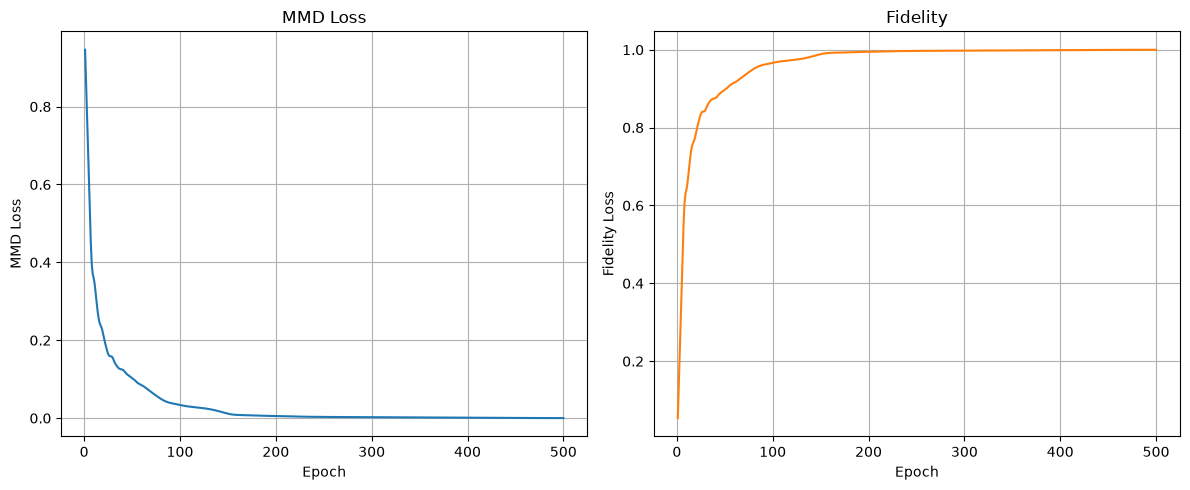


> Training finished.
Number of qubits: 7
Circuit depth (layers): 10
Number of parameters: 70
Final MMD loss: 0.99992167


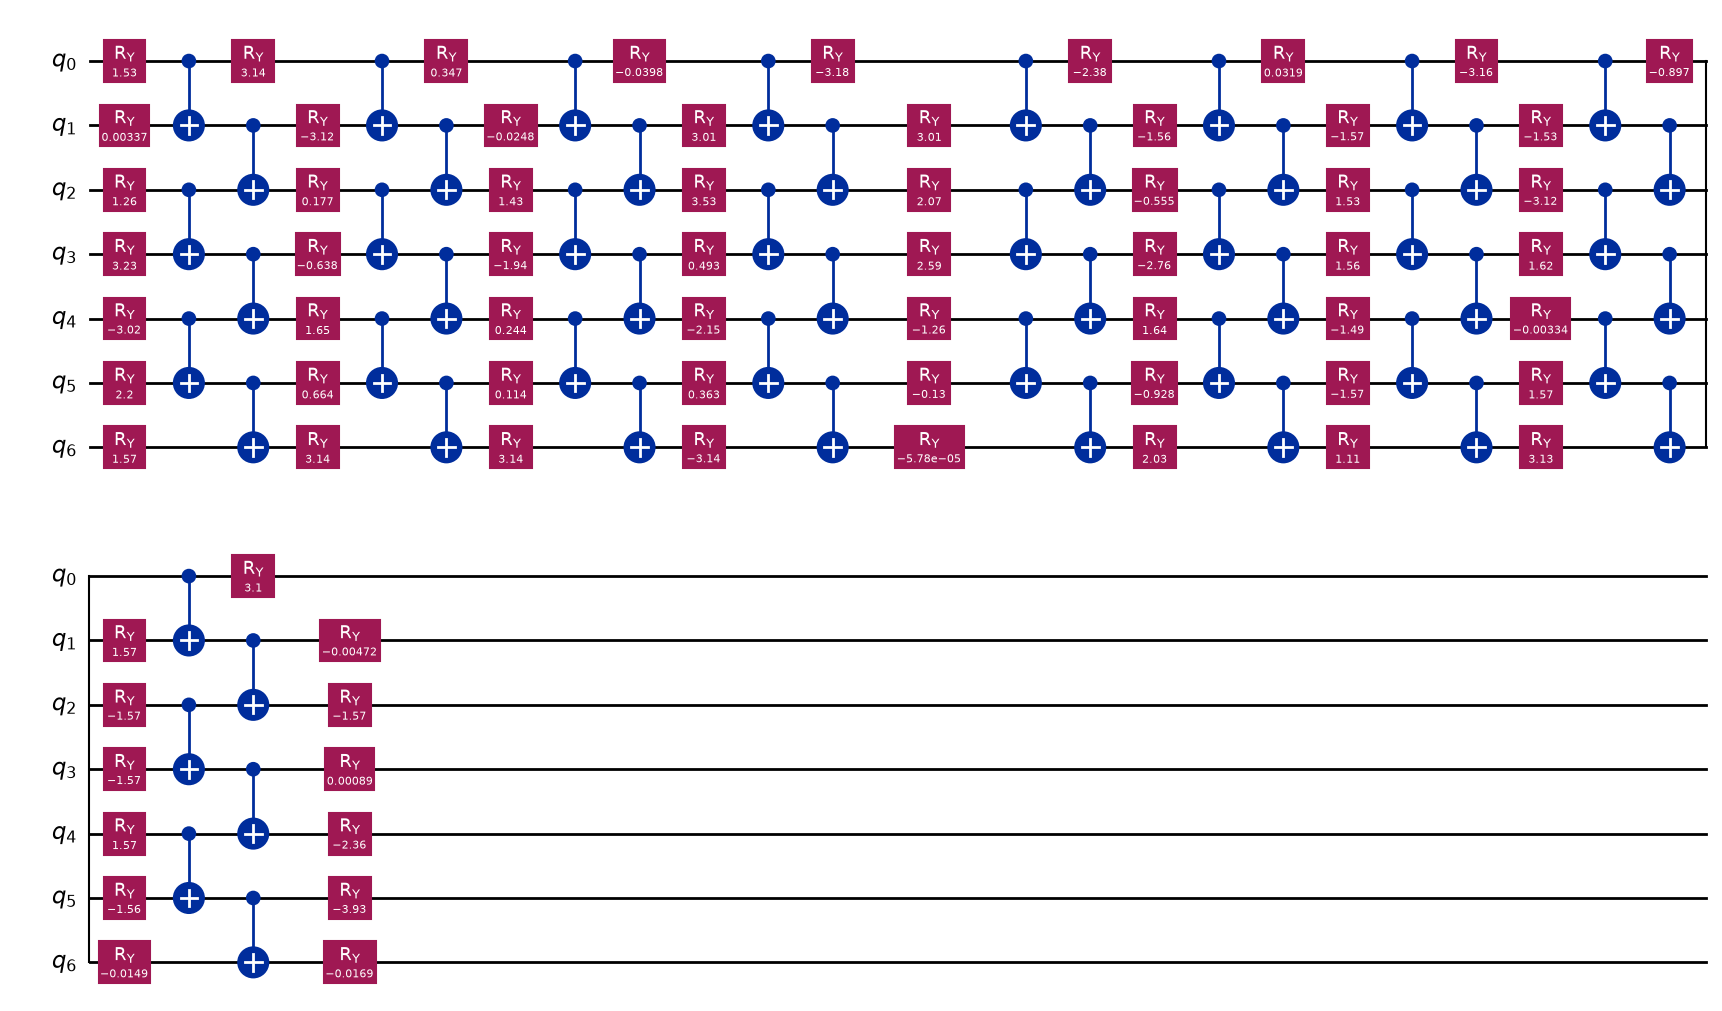


Data =  [[0 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 0 1 1]
 [0 1 0 0]
 [0 1 0 1]
 [0 1 1 0]
 [0 1 1 1]
 [1 0 0 0]
 [1 0 0 1]
 [1 0 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [1 1 0 1]
 [1 1 1 0]
 [1 1 1 1]]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99992167


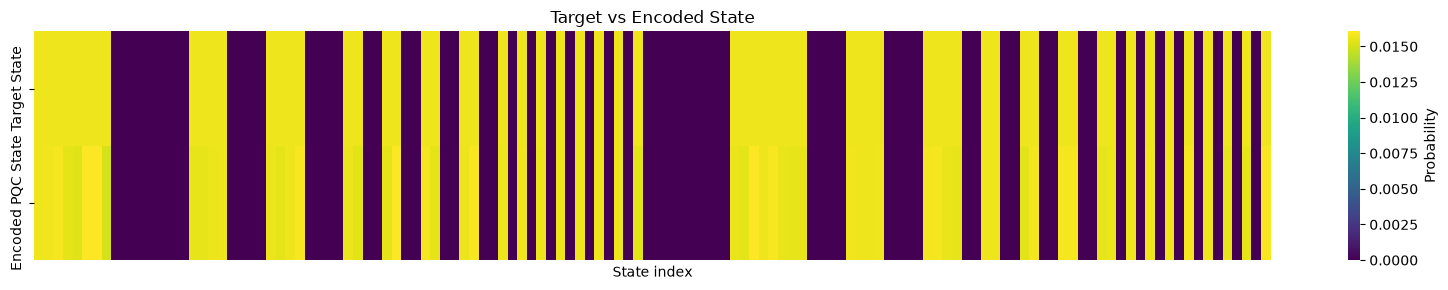

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

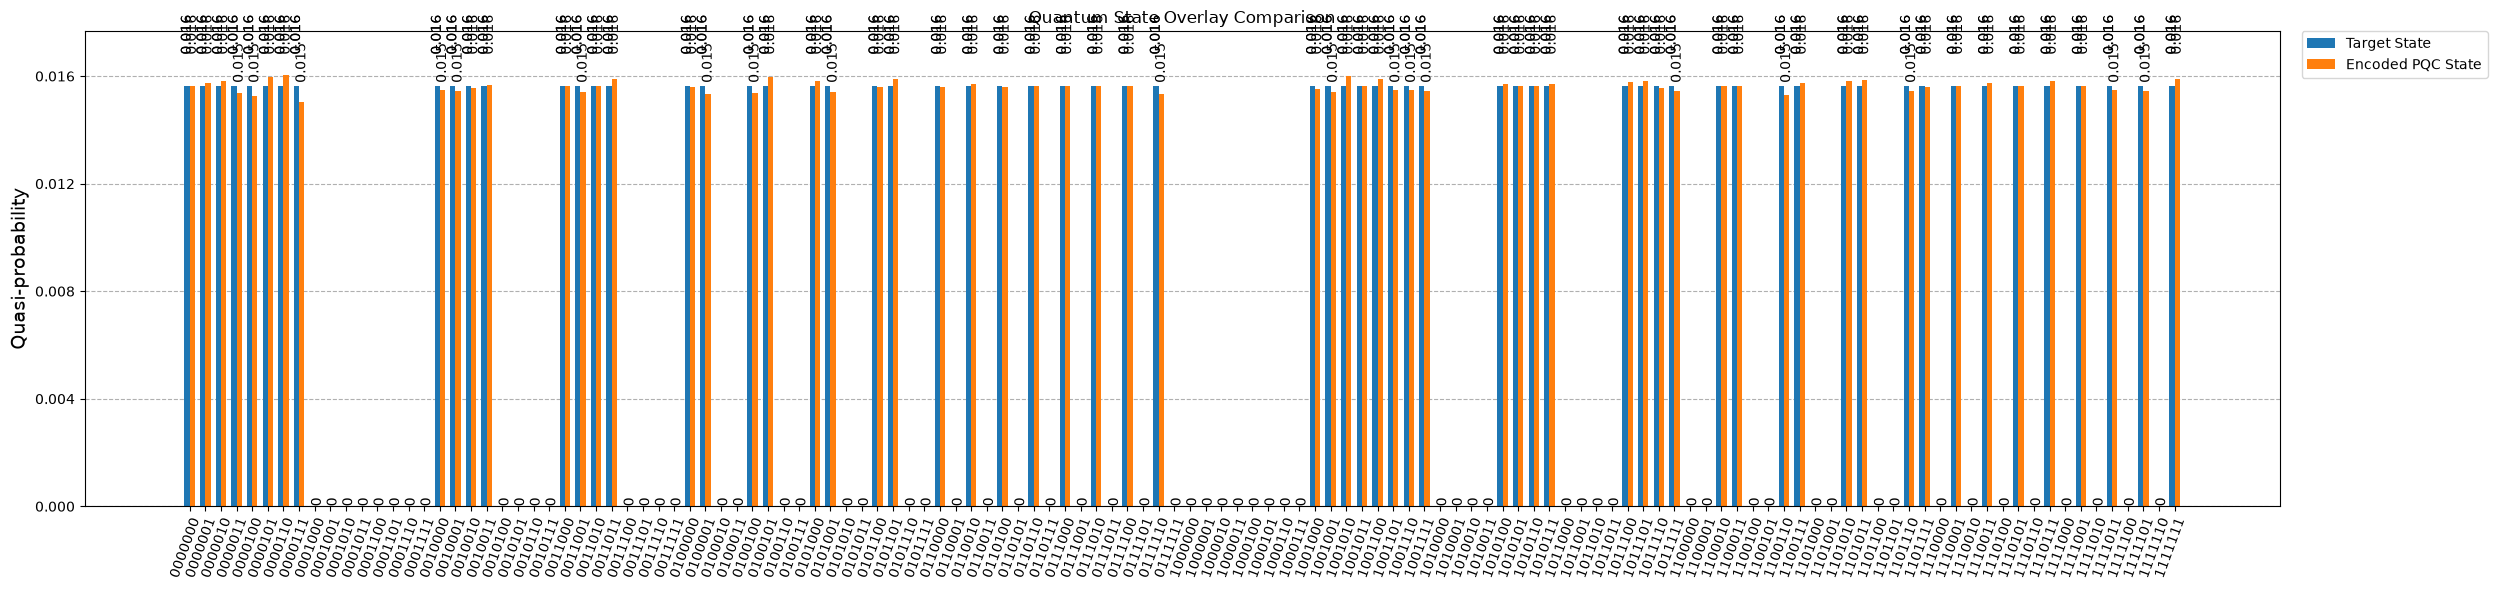


TARGET STATE
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +0.125                   +0.000                   
0                        1                        +0.125                   +0.000                   
0                        2                        +0.125                   +0.000                   
0                        3                        +0.125                   +0.000                   
1                        0                        +0.125                   +0.000                   
1                        1                        +0.125                   +0.000                   
1                        2                        +0.125                   +0.000                   
1                        3                        +0.000                   +0

<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.12502101228746448+0j)
|0000001> : (-0.12543132521720535+0j)
|0000010> : (-0.12577175387755732+0j)
|0000011> : (-0.1239927046495167+0j)
|0000100> : (-0.1236058149459775+0j)
|0000101> : (-0.1264001205052463+0j)
|0000110> : (-0.12672672242987248+0j)
|0000111> : (-0.1225764624964916+0j)
|0001000> : (0.0006946964242330881+0j)
|0001001> : (-0.00048128484332223107+0j)
|0001010> : (6.171979834962078e-05+0j)
|0001011> : (0.0011845602298019104+0j)
|0001100> : (0.0013038897650280846+0j)
|0001101> : (-0.0009300769516550968+0j)
|0001110> : (-0.0019335090001032361+0j)
|0001111> : (0.0016848706440805224+0j)
|0010000> : (-0.12438215391375078+0j)
|0010001> : (-0.12424100380650954+0j)
|0010010> : (-0.12473767386708833+0j)
|0010011> : (-0.12519427352205073+0j)
|0010100> : (0.00047537983983810884+0j)
|0010101> : (-0.0014859213487147882+0j)
|0010110> : (-0.0003030772037427389+0j)
|0010111> : (0.0005285693701568805+0j)
|0011000> : (-0.12495582822720566+0j)
|0011

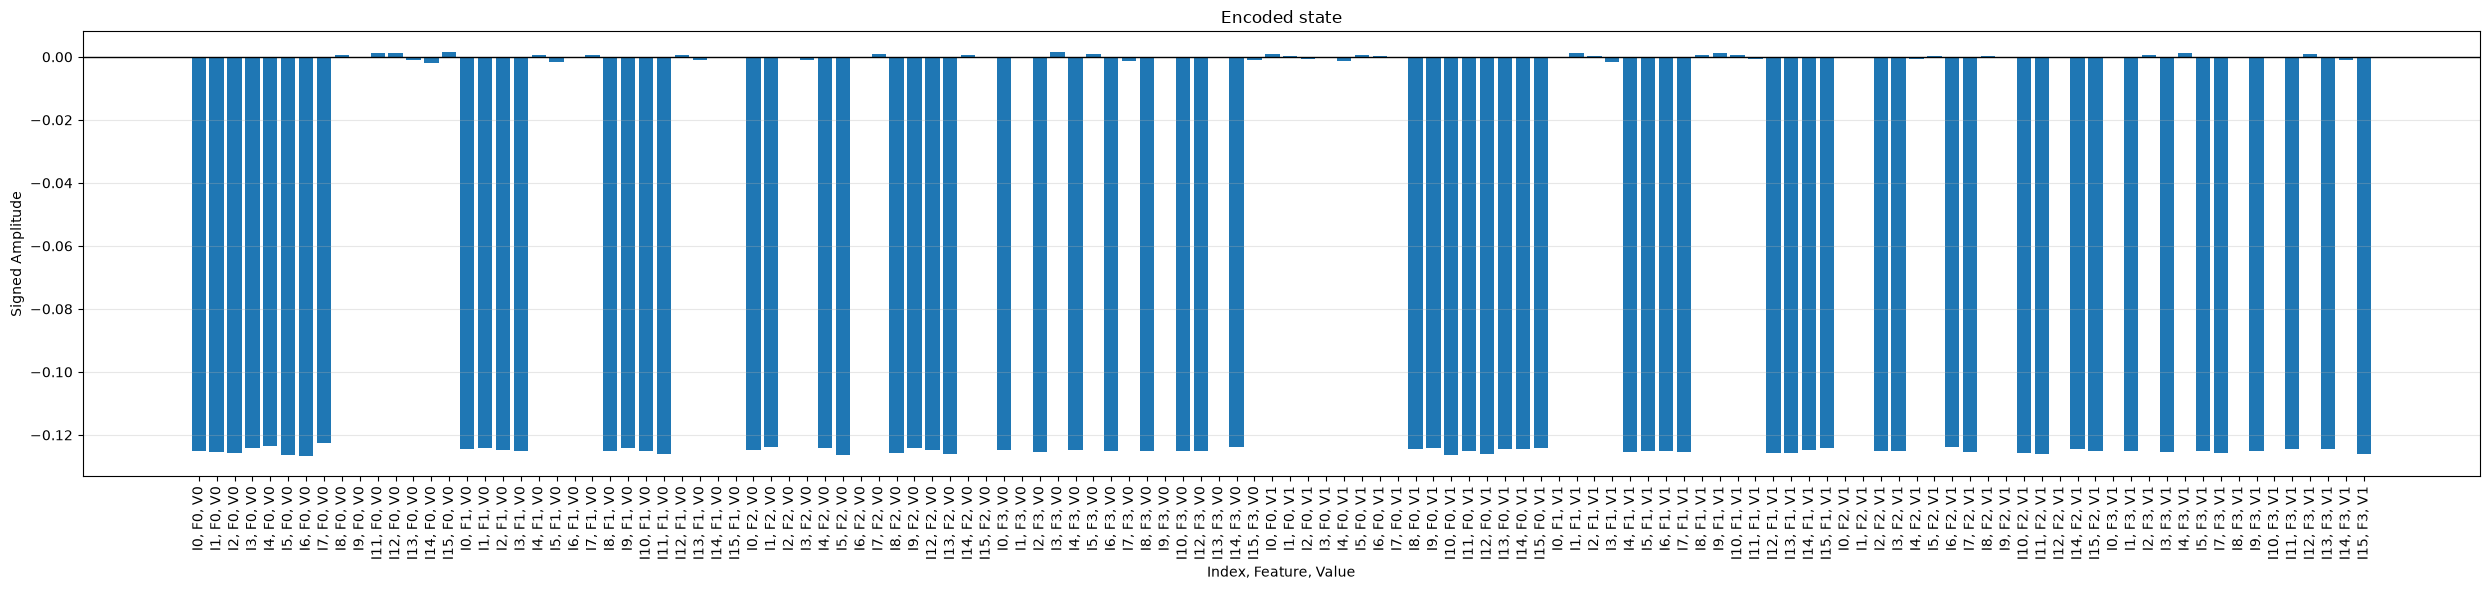

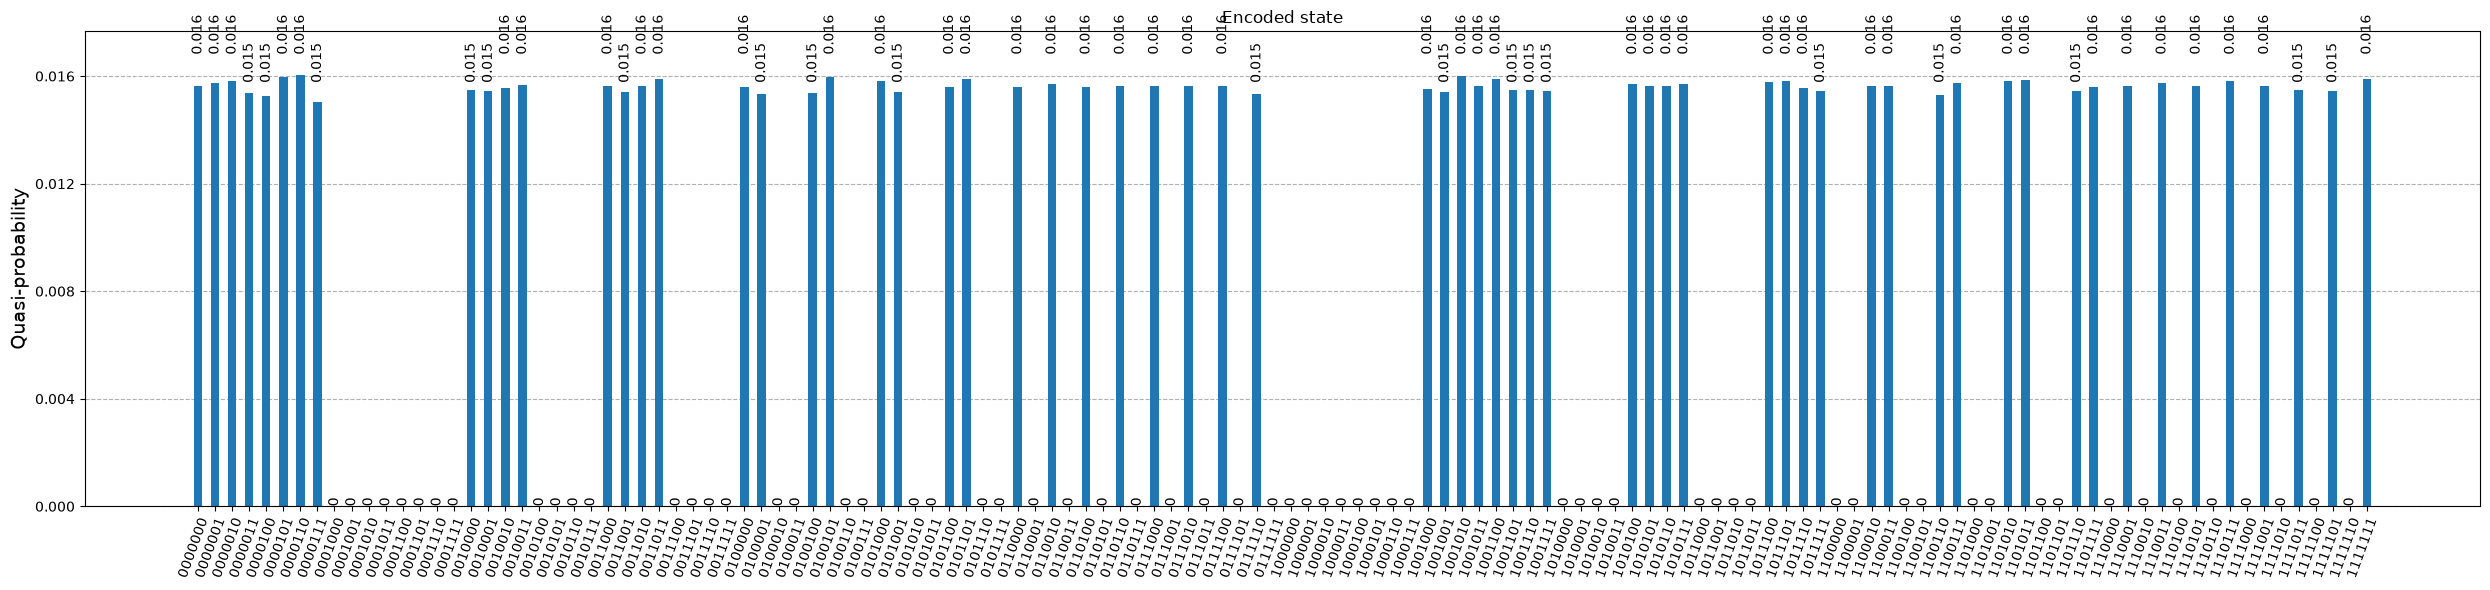

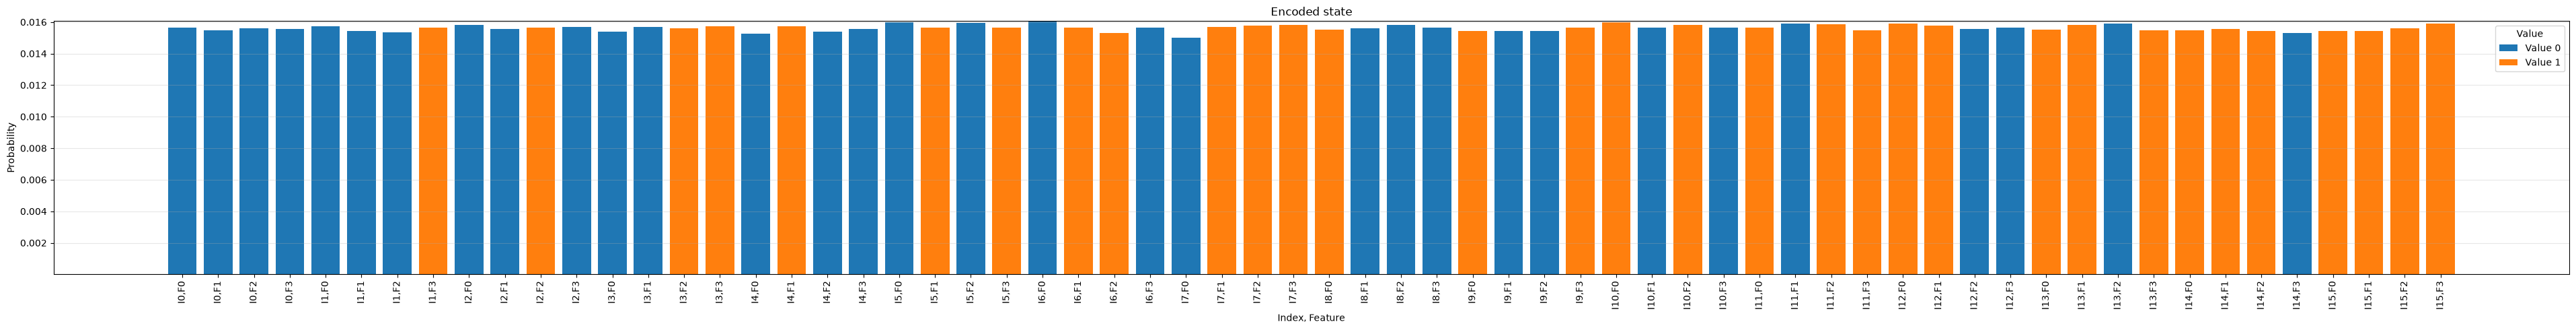


Encoded state
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.125                   +0.001                   
0                        1                        -0.124                   -0.000                   
0                        2                        -0.125                   -0.000                   
0                        3                        -0.125                   -0.000                   
1                        0                        -0.125                   +0.000                   
1                        1                        -0.124                   +0.001                   
1                        2                        -0.124                   -0.000                   
1                        3                        -0.000                   -

In [121]:
A_parameters_neqr_fidelity = encoder.generate_encoding(dataset, scheme="NEQR", depth=pqc_depth_for_dataset_encoder, epochs=500, learning_rate=0.08, loss_function_type="FIDELITY")


> Preparing query target state....

Number of feature qubits (n_data_q): 2
Number of value qubits (n_value_q): 1
Total number of qubits (total_qubits): 3
Total number of states (total_num_states): 8

Amplitude =  0.5

Prepared target state = 


<IPython.core.display.Latex object>


Target norm: 1.0
Nonzero amplitudes: 4

> Starting training....

Number of parameters = 9

> Using adam optimization....
Epoch 1 - Loss 0.983718913374449 - Fidelity 0.016281086625550986
Epoch 2 - Loss 0.9817817834380804 - Fidelity 0.018218216561919603
Epoch 3 - Loss 0.9797306386055765 - Fidelity 0.020269361394423483
Epoch 4 - Loss 0.9775636425152678 - Fidelity 0.022436357484732182
Epoch 5 - Loss 0.9752788566653722 - Fidelity 0.024721143334627854
Epoch 6 - Loss 0.9728742649838763 - Fidelity 0.027125735016123684
Epoch 7 - Loss 0.9703477976071043 - Fidelity 0.0296522023928957
Epoch 8 - Loss 0.9676973537756872 - Fidelity 0.03230264622431276
Epoch 9 - Loss 0.9649208237395444 - Fidelity 0.035079176260455605
Epoch 10 - Loss 0.9620161095326679 - Fidelity 0.03798389046733206
Epoch 11 - Loss 0.9589811444350878 - Fidelity 0.041018855564912214
Epoch 12 - Loss 0.9558139108834064 - Fidelity 0.04418608911659363
Epoch 13 - Loss 0.9525124565219936 - Fidelity 0.04748754347800646
Epoch 14 - Loss 0.94907

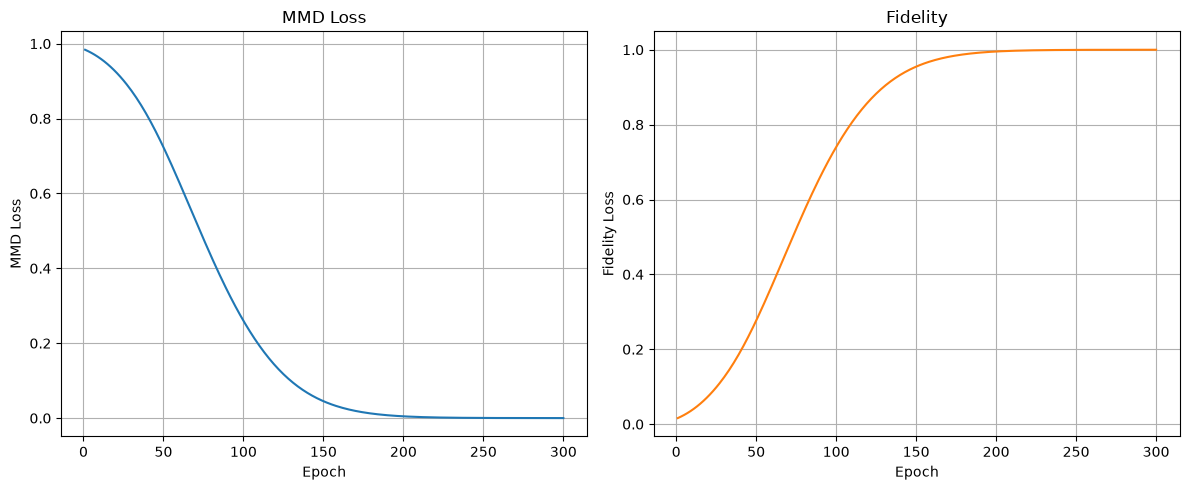


> Training finished.
Number of qubits: 3
Circuit depth (layers): 3
Number of parameters: 9
Final MMD loss: 0.99997081


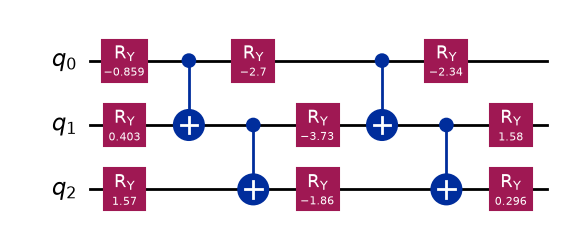


Data =  [0 0 0 0]

Target state:


<IPython.core.display.Latex object>


Encoded state: 


<IPython.core.display.Latex object>


Fidelity between target and encoded state: 0.99997081


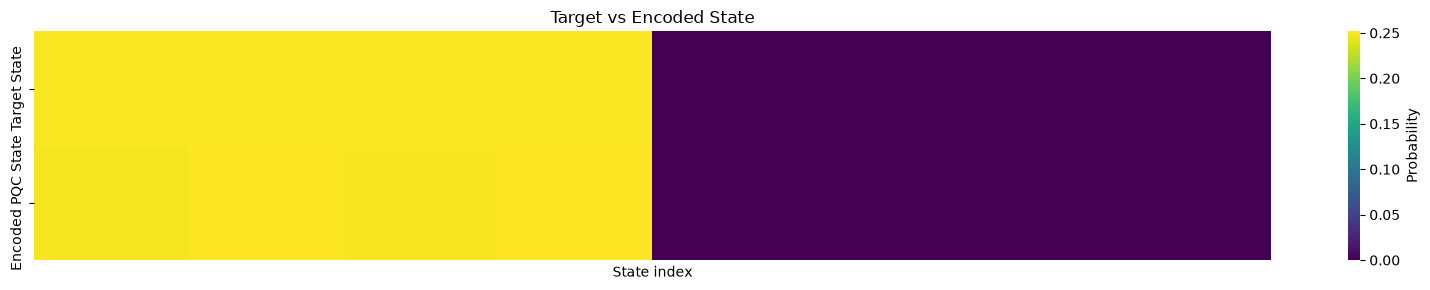

<Axes: title={'center': 'Target vs Encoded State'}, xlabel='State index'>

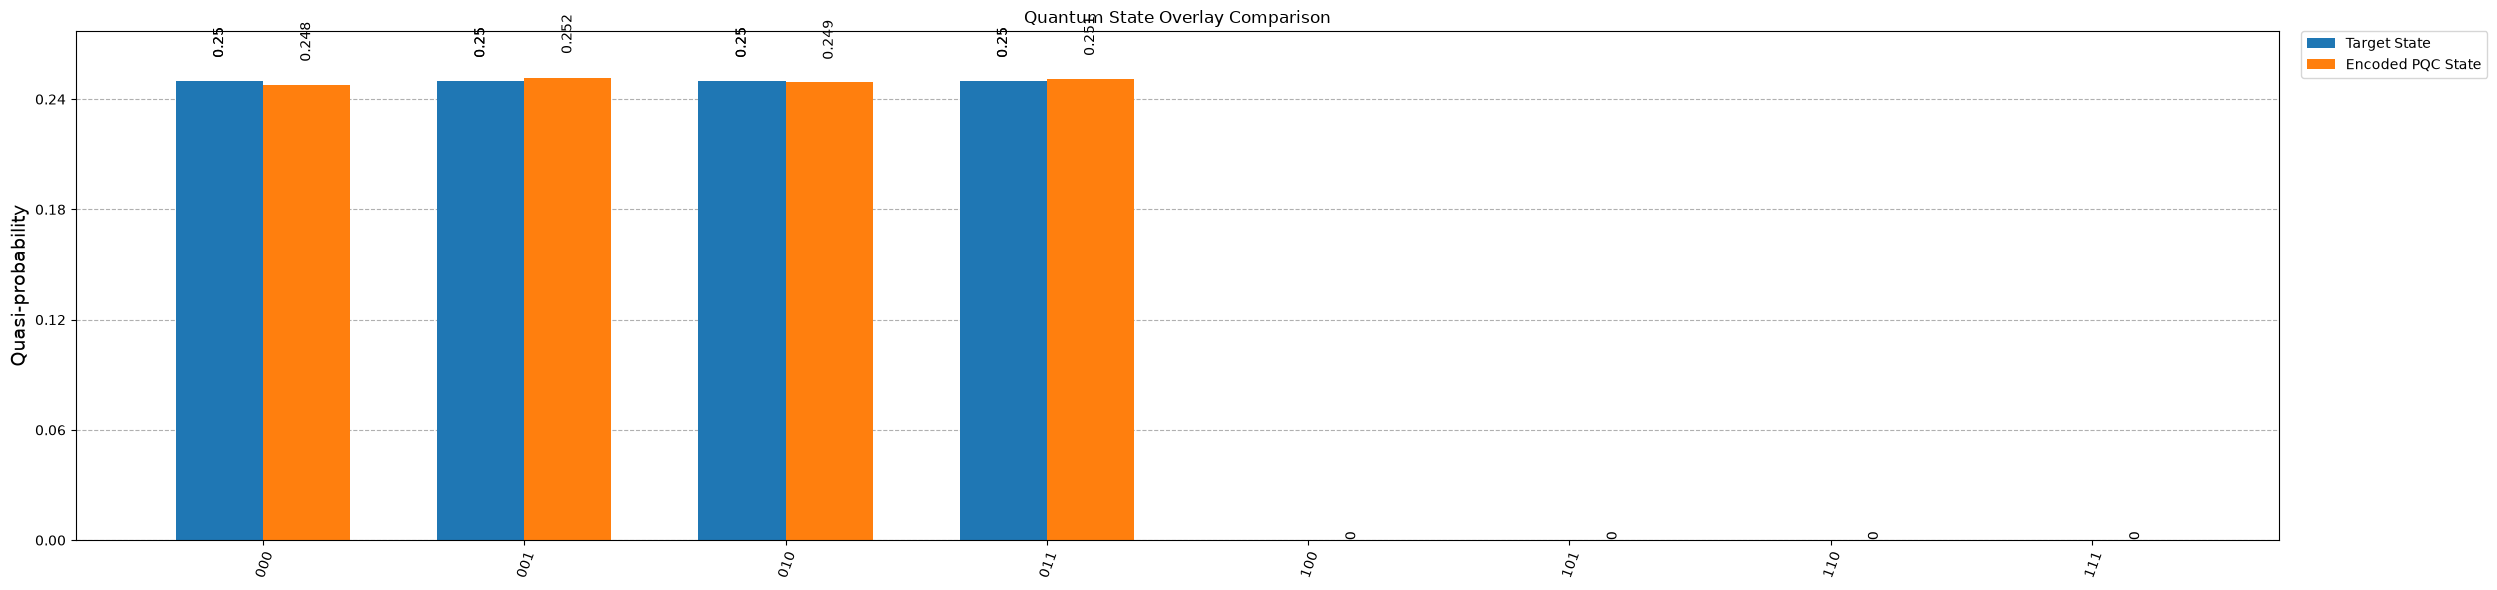


TARGET STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.500                   +0.000                   
1                        +0.500                   +0.000                   
2                        +0.500                   +0.000                   
3                        +0.500                   +0.000                   

ENCODED STATE
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.498                   -0.001                   
1                        +0.502                   -0.002                   
2                        +0.499                   -0.001                   
3                        +0.501                   +0.004                   

State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|000> : (0.49792809754484013+0j)
|001> : (0.5017400773683177+0j)
|010> : (0.49917227591628804+0j)
|011> : (0.501130363588292+0j)
|100> : (-0.000643469350285295+0j)
|101> : (-0.0022741509159757106+0j)
|110> : (-0.000721991607744367+0j)
|111> : (0.0037141617027819217+0j)


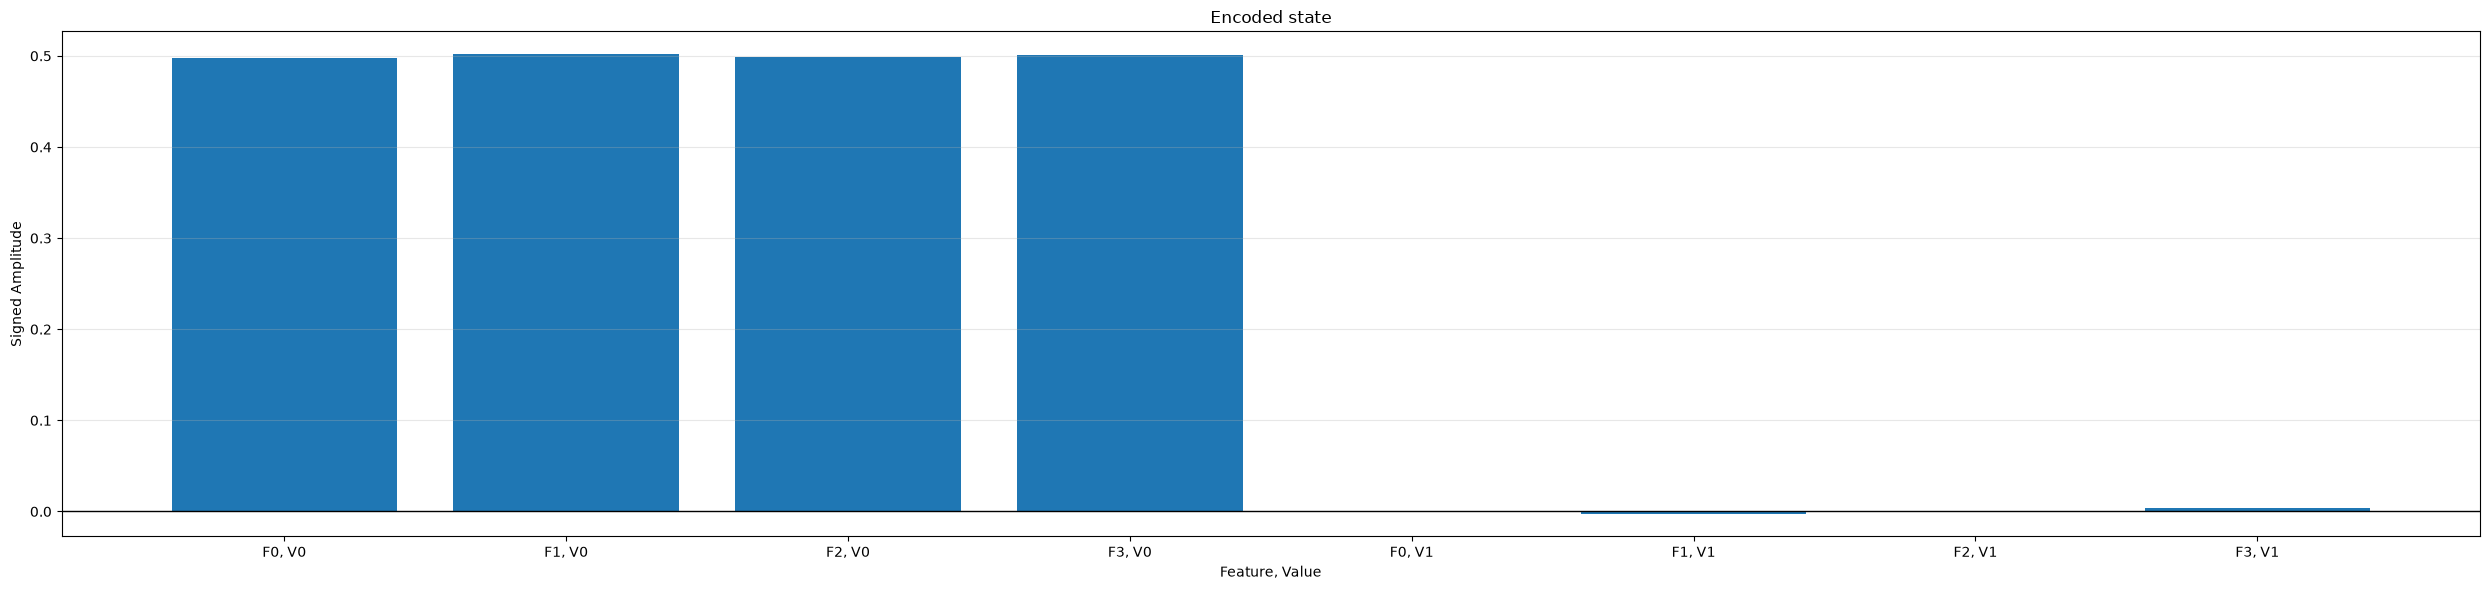

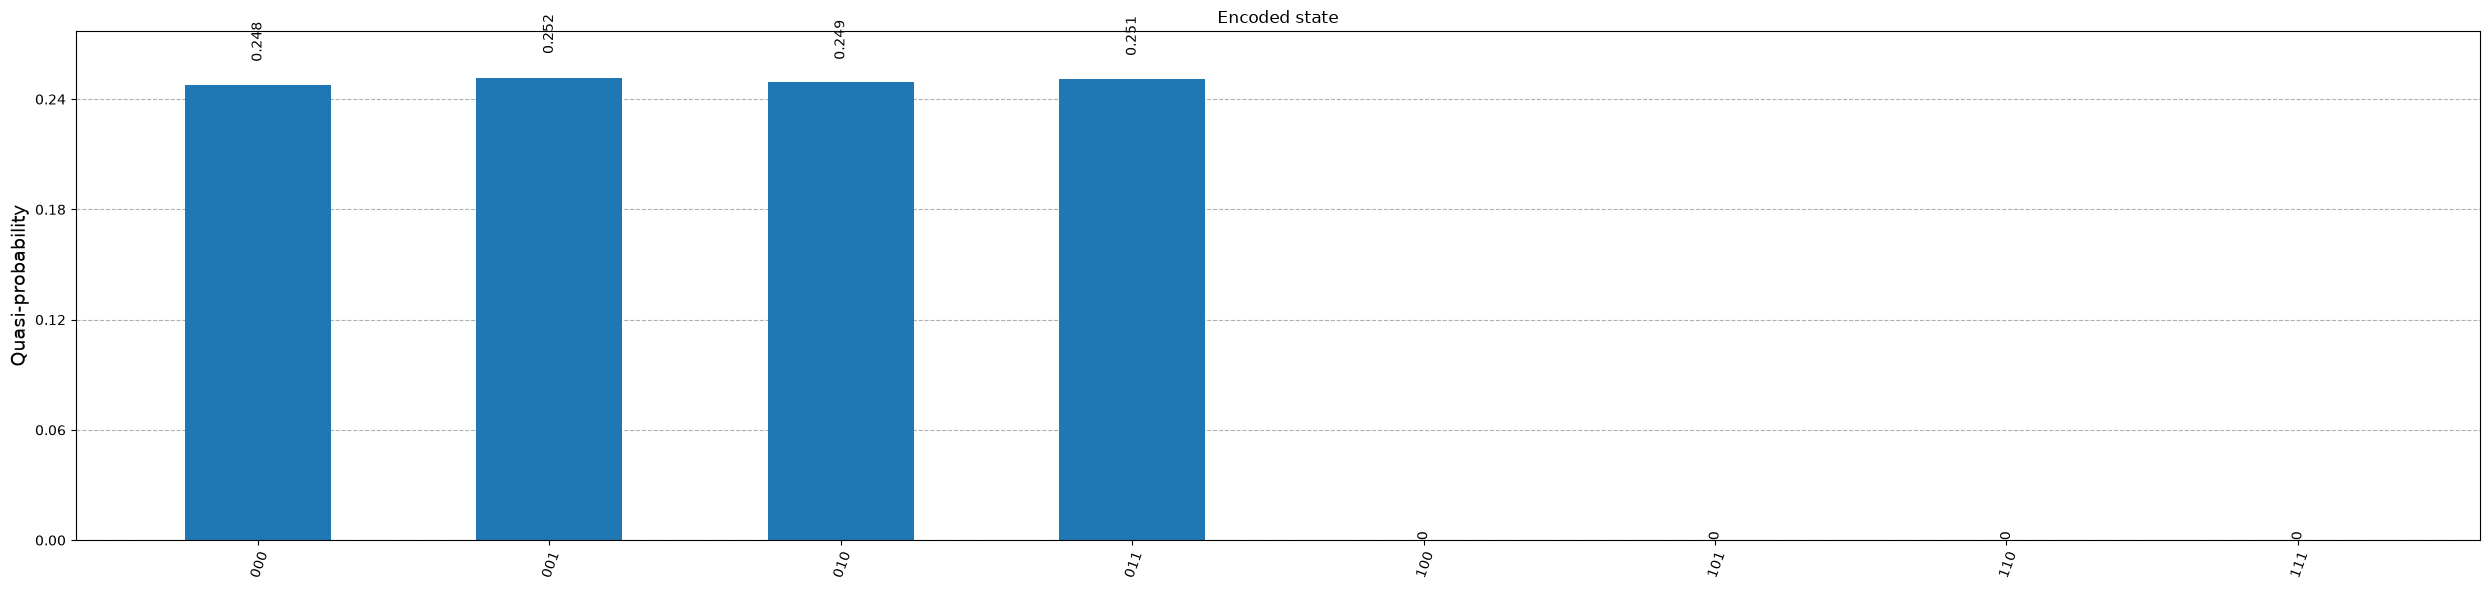

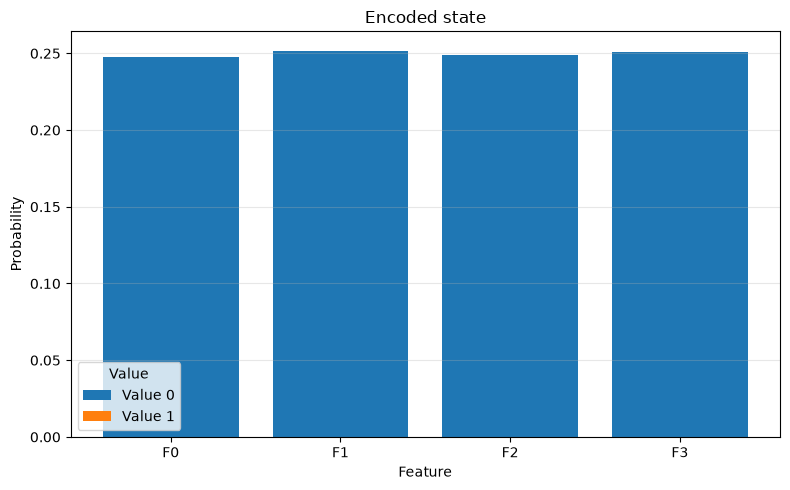


Encoded state
Feature                  Value-0-Amplitude        Value-1-Amplitude        
---------------------------------------------------------------------------
0                        +0.498                   -0.001                   
1                        +0.502                   -0.002                   
2                        +0.499                   -0.001                   
3                        +0.501                   +0.004                   


In [122]:
B_parameters_neqr_fidelity = encoder.generate_encoding(query, scheme="NEQR", depth=pqc_depth_for_query_encoder, epochs=300, learning_rate=0.005, loss_function_type="FIDELITY")

## <u>**U operation**</u>

U = (B† ⊗ I_I) A

In [123]:
n_index_q = math.ceil(math.log2(len(dataset)))
n_feature_q = math.ceil(math.log2(len(dataset[0])))

max_value = int(np.max(dataset))
n_value_q = max(1, math.ceil(math.log2(max_value + 1)))
print("Index qubits = ", n_index_q)
print("Feature qubits = ", n_feature_q)
print("Value qubits = ", n_value_q)

Index qubits =  4
Feature qubits =  2
Value qubits =  1


In [124]:
A = encoder.pqc(
    A_parameters_neqr_fidelity, depth=pqc_depth_for_dataset_encoder, n_qubits=(n_index_q + n_feature_q + n_value_q)
)

In [125]:
B = encoder.pqc(
    B_parameters_neqr_fidelity, depth=pqc_depth_for_query_encoder, n_qubits=(n_value_q + n_feature_q)
)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (1+0j)


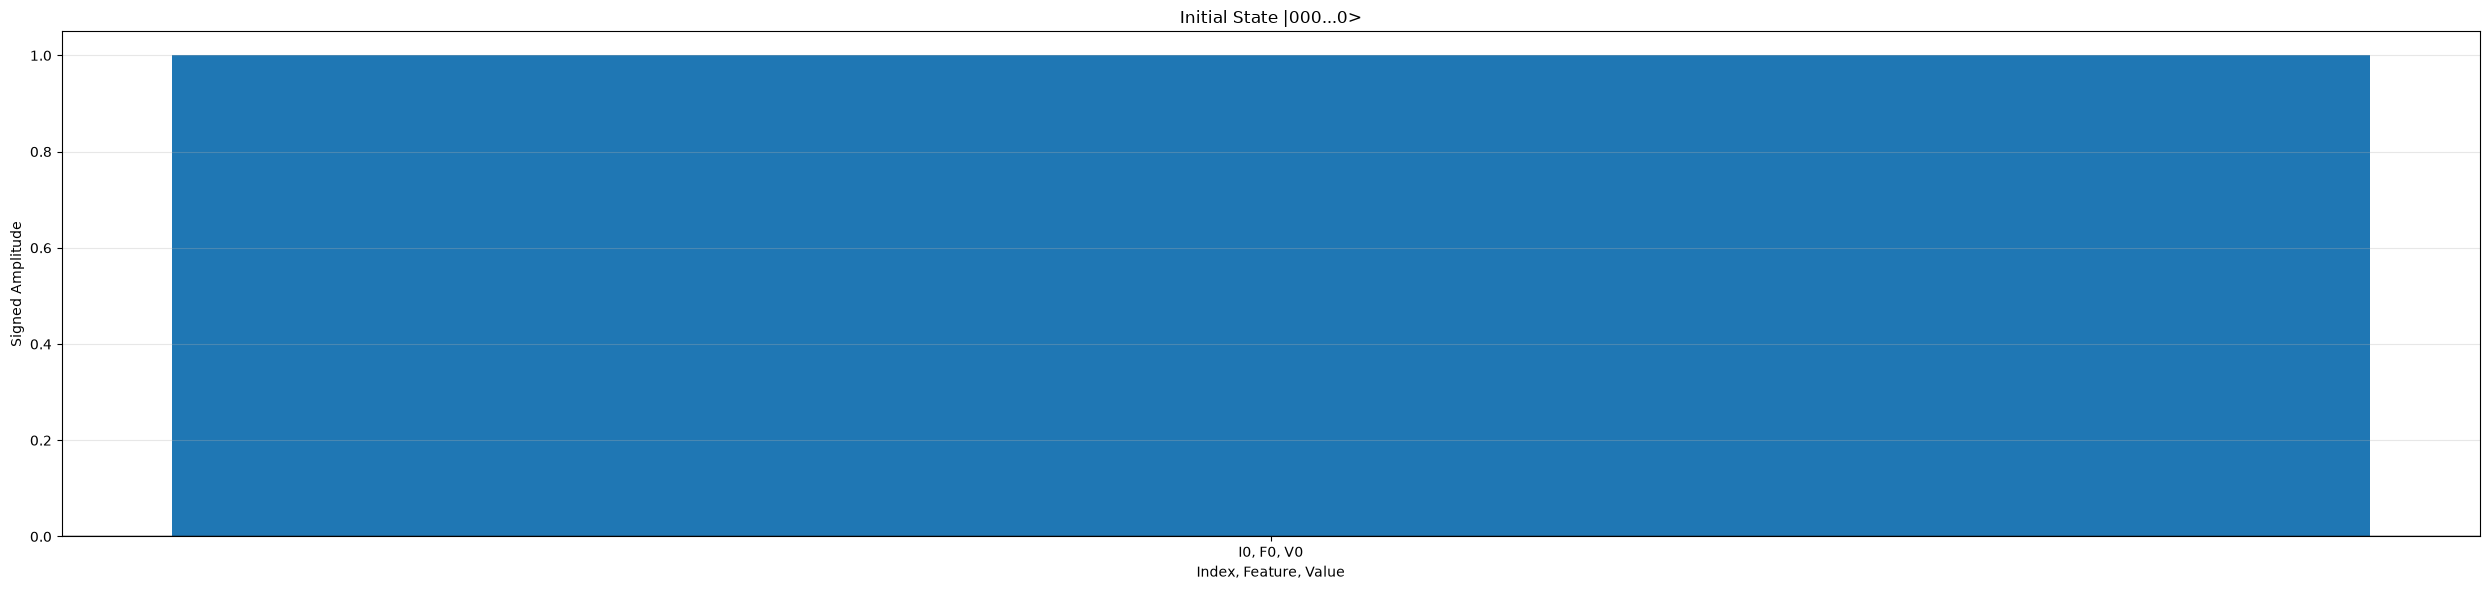

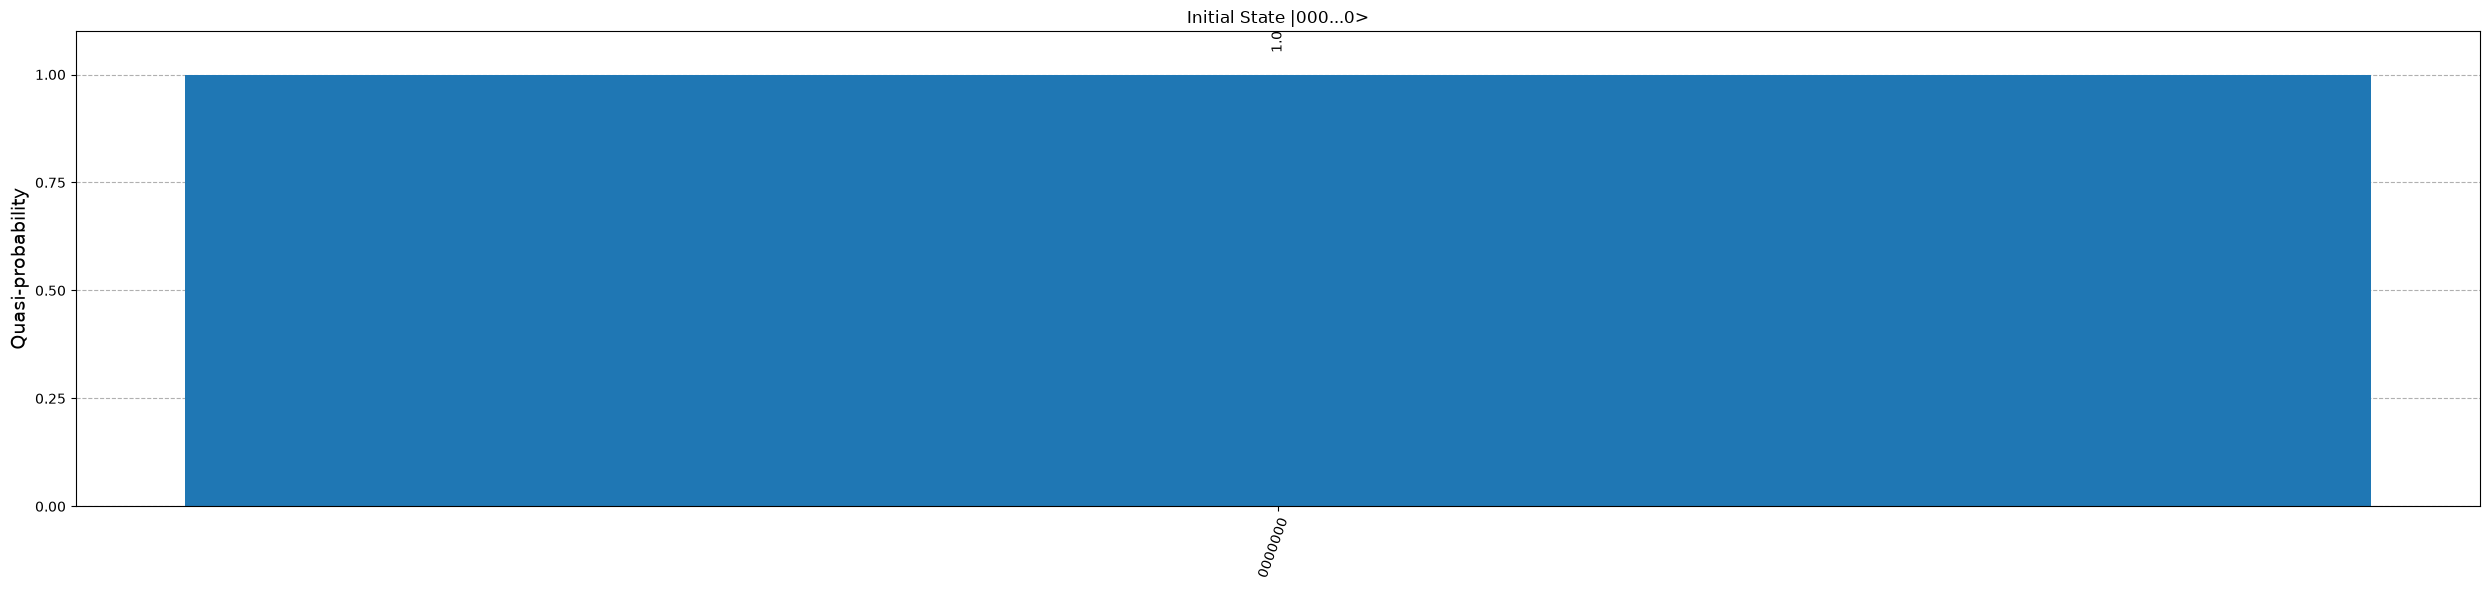

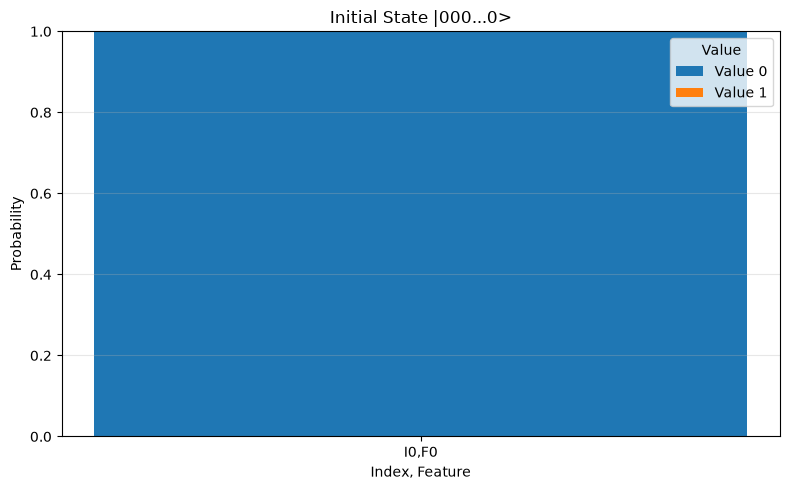


Initial State |000...0>
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        +1.000                   +0.000                   


In [126]:
value_reg = QuantumRegister(n_value_q)
feature_reg = QuantumRegister(n_feature_q)
index_reg = QuantumRegister(n_index_q)
qc = QuantumCircuit(value_reg, feature_reg, index_reg)

initial_state = Statevector.from_instruction(qc)
state_analysis(initial_state, "Initial State |000...0>", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.12502101228746448+0j)
|0000001> : (-0.12543132521720535+0j)
|0000010> : (-0.12577175387755732+0j)
|0000011> : (-0.1239927046495167+0j)
|0000100> : (-0.1236058149459775+0j)
|0000101> : (-0.1264001205052463+0j)
|0000110> : (-0.12672672242987248+0j)
|0000111> : (-0.1225764624964916+0j)
|0001000> : (0.0006946964242330881+0j)
|0001001> : (-0.00048128484332223107+0j)
|0001010> : (6.171979834962078e-05+0j)
|0001011> : (0.0011845602298019104+0j)
|0001100> : (0.0013038897650280846+0j)
|0001101> : (-0.0009300769516550968+0j)
|0001110> : (-0.0019335090001032361+0j)
|0001111> : (0.0016848706440805224+0j)
|0010000> : (-0.12438215391375078+0j)
|0010001> : (-0.12424100380650954+0j)
|0010010> : (-0.12473767386708833+0j)
|0010011> : (-0.12519427352205073+0j)
|0010100> : (0.00047537983983810884+0j)
|0010101> : (-0.0014859213487147882+0j)
|0010110> : (-0.0003030772037427389+0j)
|0010111> : (0.0005285693701568805+0j)
|0011000> : (-0.12495582822720566+0j)
|0011

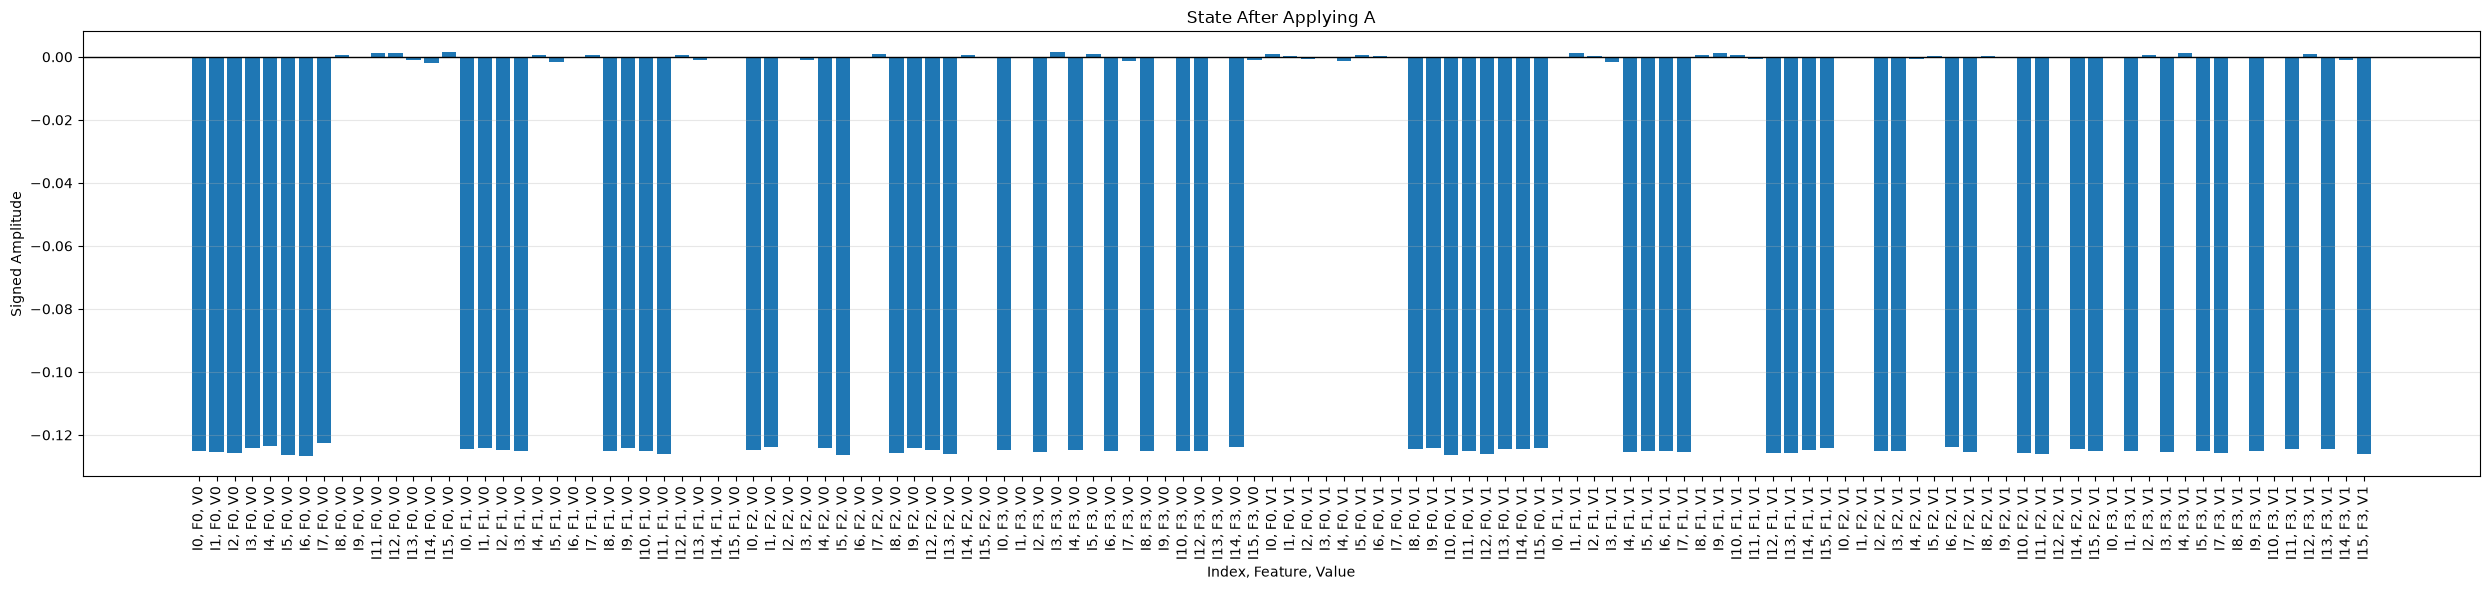

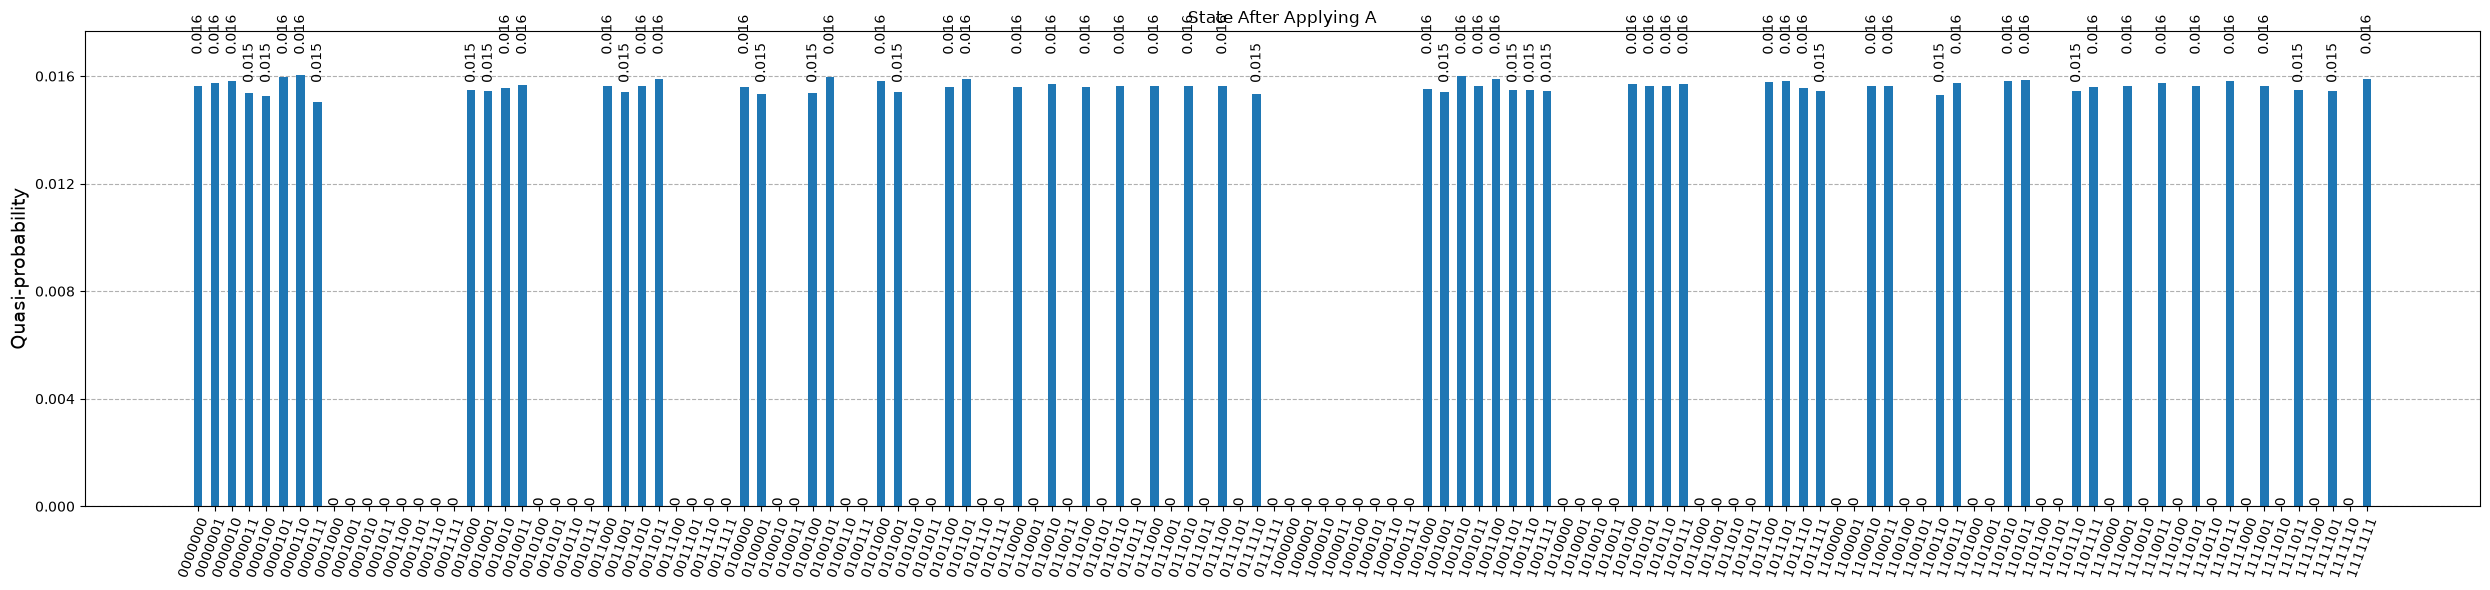

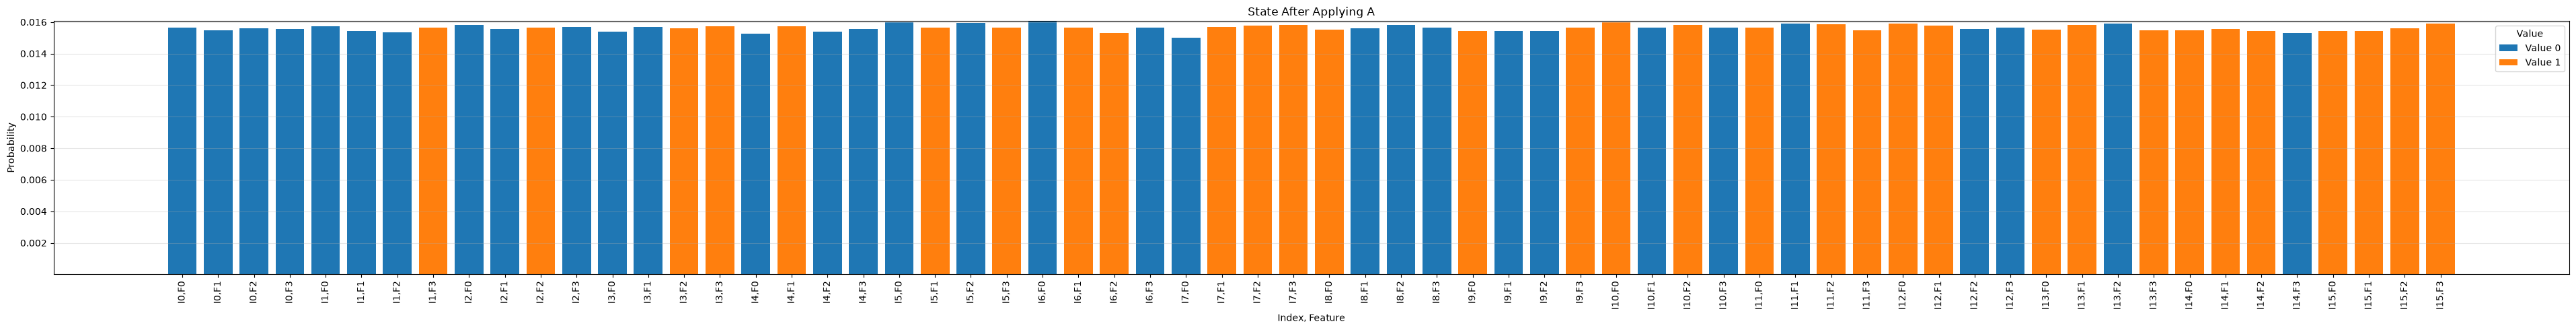


State After Applying A
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.125                   +0.001                   
0                        1                        -0.124                   -0.000                   
0                        2                        -0.125                   -0.000                   
0                        3                        -0.125                   -0.000                   
1                        0                        -0.125                   +0.000                   
1                        1                        -0.124                   +0.001                   
1                        2                        -0.124                   -0.000                   
1                        3                        -0.000           

In [127]:
qc.compose(A, inplace=True)
qc.barrier()

state_after_A = Statevector.from_instruction(qc)

state_analysis(state_after_A, "State After Applying A", n_value_q, n_feature_q, n_index_q)


State vector:


<IPython.core.display.Latex object>


Basis states and amplitudes:
|0000000> : (-0.25010046308200445+0j)
|0000001> : (0.0013529537444742284+0j)
|0000010> : (-0.0021594943345779193+0j)
|0000011> : (0.00354157337144804+0j)
|0000100> : (-0.14997210476730266+0j)
|0000101> : (-0.172668109986324+0j)
|0000110> : (0.06318169865386863+0j)
|0000111> : (0.07764612863672578+0j)
|0001000> : (0.0007377868667725727+0j)
|0001001> : (0.0008197062295989986+0j)
|0001010> : (0.00041813531780072674+0j)
|0001011> : (0.0023230237435112695+0j)
|0001100> : (-0.0001315179340510124+0j)
|0001101> : (0.0005450962689261248+0j)
|0001110> : (-0.0010968384171815564+0j)
|0001111> : (0.0017200705353518726+0j)
|0010000> : (-0.24926904516666545+0j)
|0010001> : (0.0009807621716814618+0j)
|0010010> : (-0.0015657827087363291+0j)
|0010011> : (0.001987310017448976+0j)
|0010100> : (-0.0001928198123248445+0j)
|0010101> : (-0.0004119459143185129+0j)
|0010110> : (-0.00013354466987848255+0j)
|0010111> : (3.5647528222160225e-05+0j)
|0011000> : (-0.2501459073780552+0j)


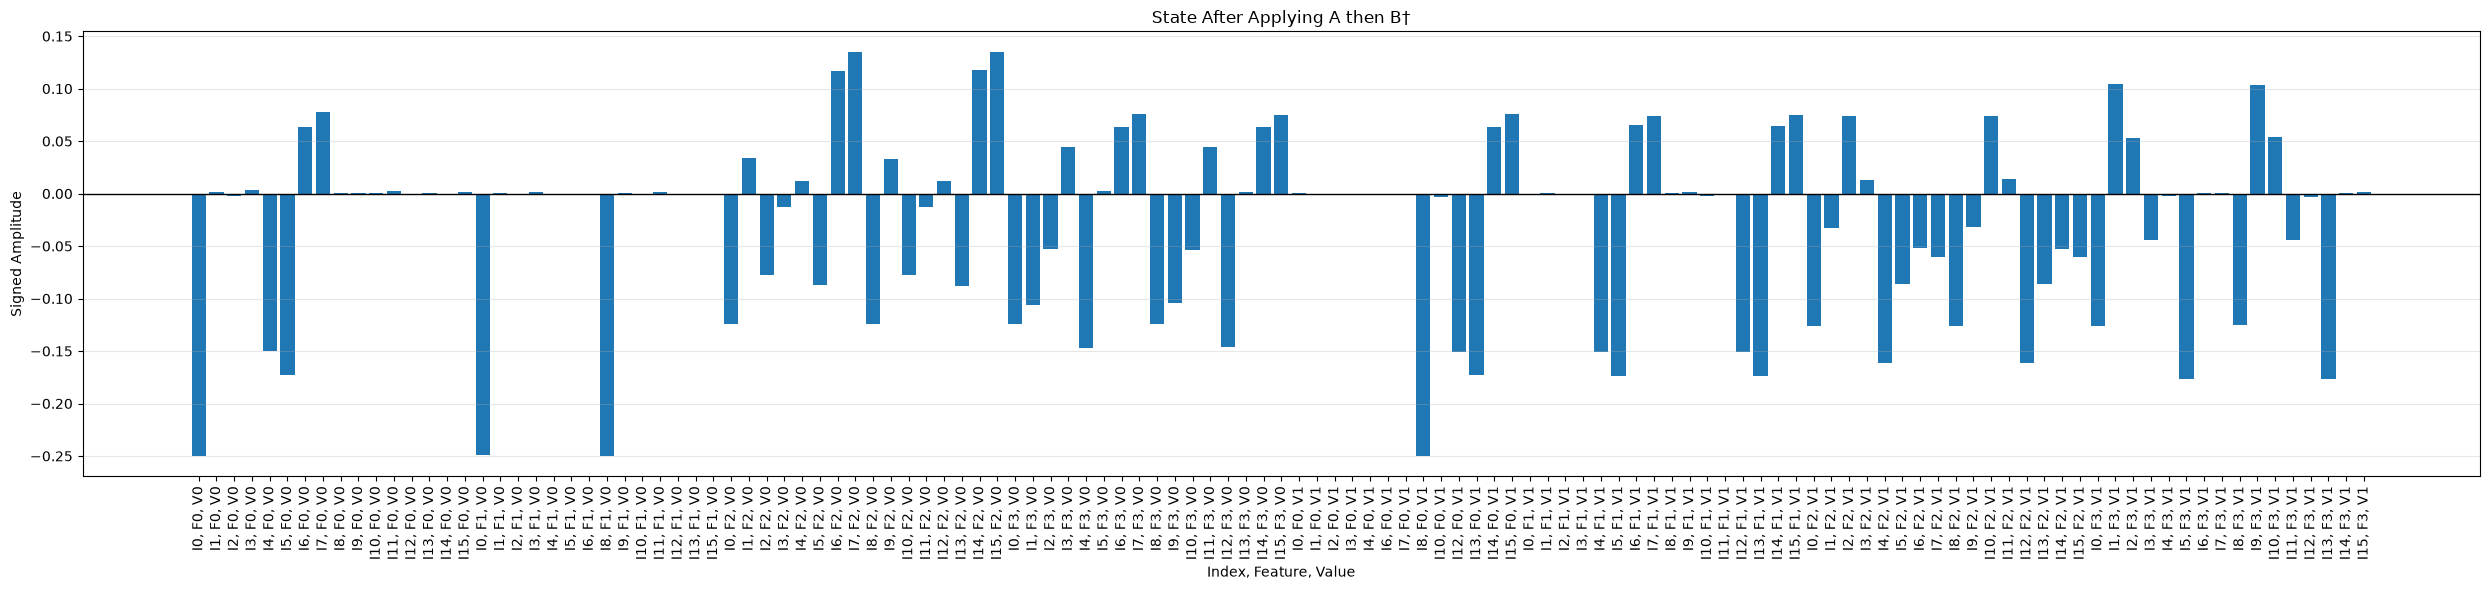

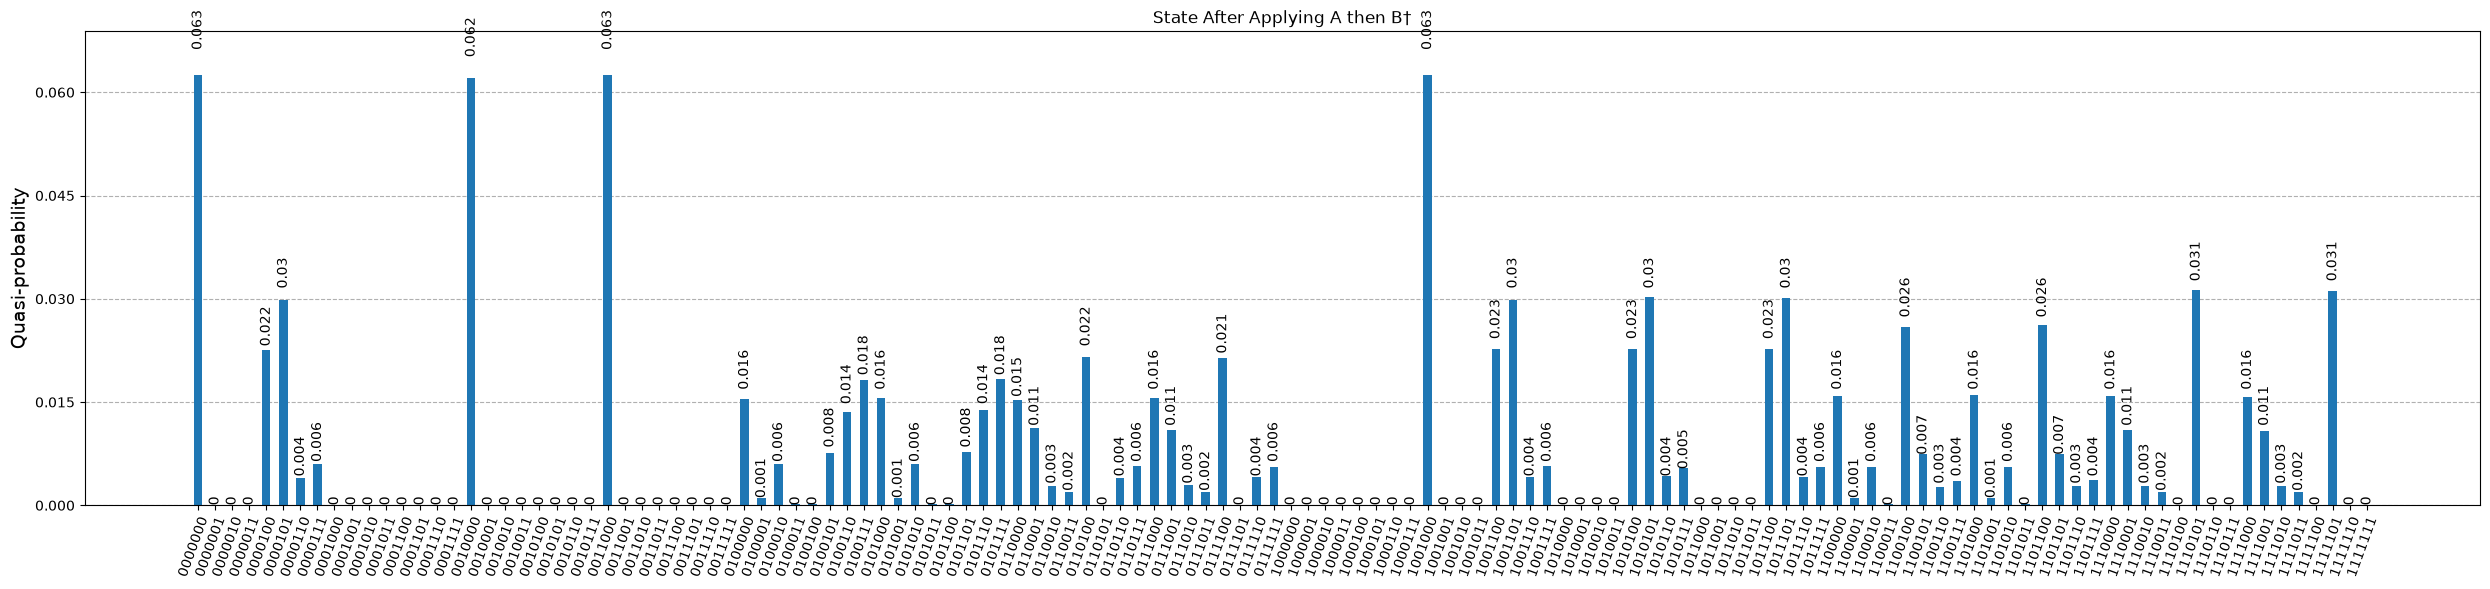

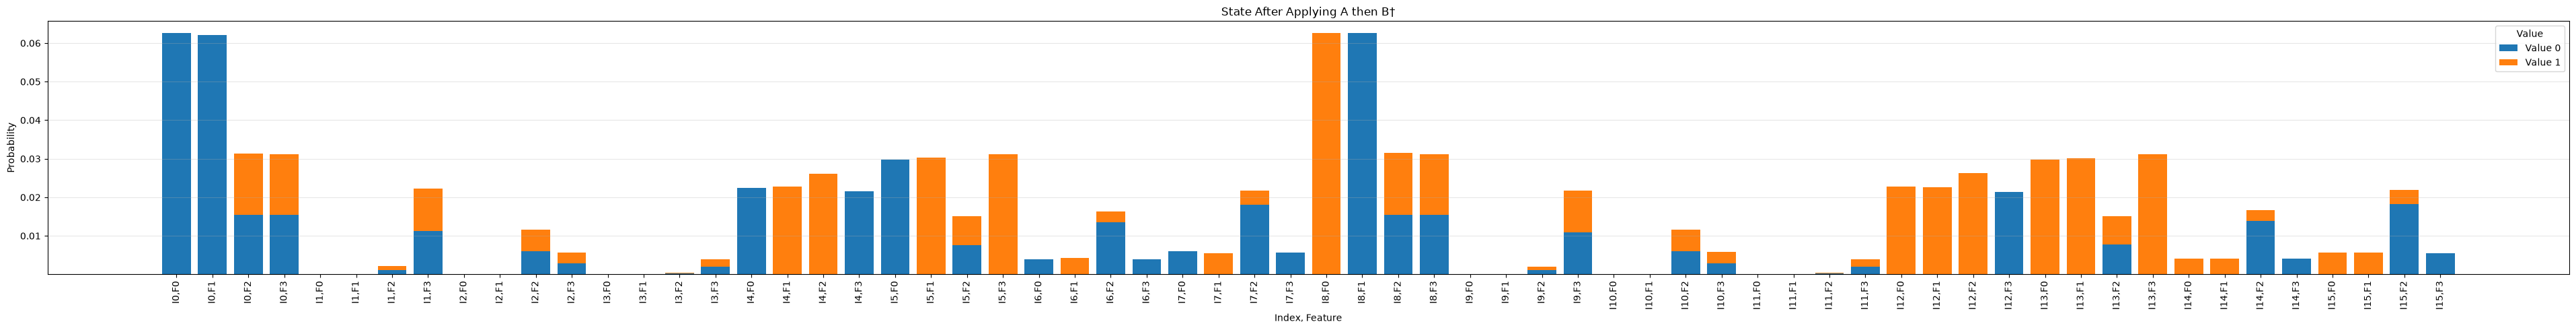


State After Applying A then B†
Row                      Feature                  Value-0-Amplitude        Value-1-Amplitude        
----------------------------------------------------------------------------------------------------
0                        0                        -0.250                   +0.000                   
0                        1                        -0.249                   -0.000                   
0                        2                        -0.125                   -0.126                   
0                        3                        -0.124                   -0.126                   
1                        0                        +0.001                   -0.000                   
1                        1                        +0.001                   +0.001                   
1                        2                        +0.034                   -0.032                   
1                        3                        -0.106   

In [128]:
qc.compose(B.inverse(), qubits=range(n_feature_q + n_value_q), inplace=True)
qc.barrier()

state_after_B_inverse = Statevector.from_instruction(qc)

state_analysis(state_after_B_inverse, "State After Applying A then B†", n_value_q, n_feature_q, n_index_q)

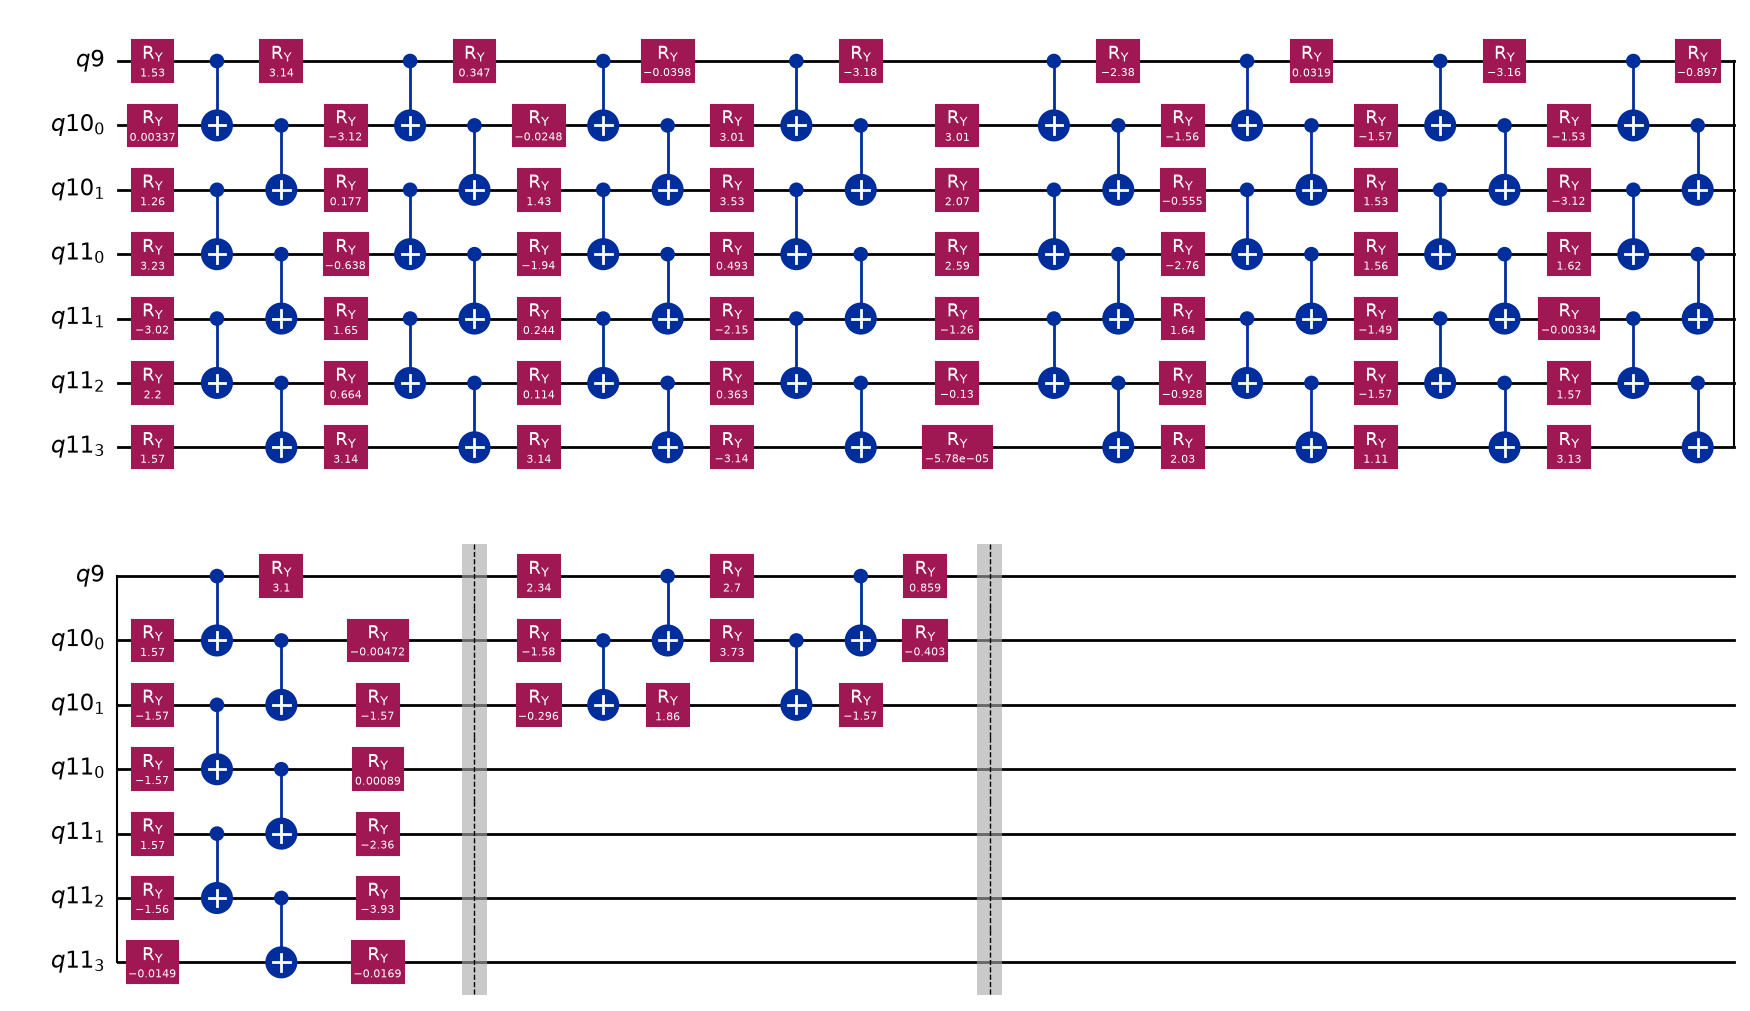

In [129]:
display(qc.draw("mpl"))

# <u>**Part 2: Use Grover Search for Image Matching**</u>

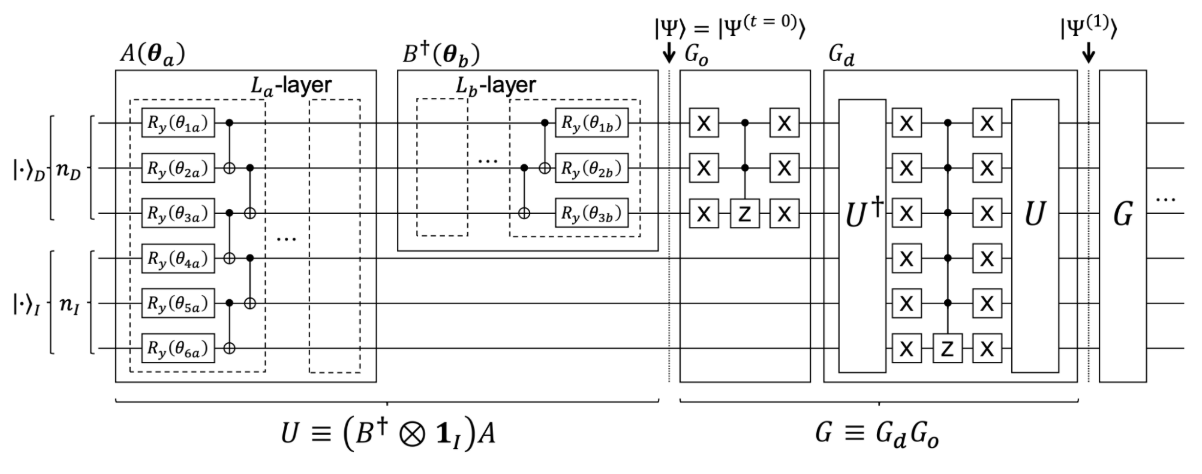

In [130]:
class GroverSearch:
  def pqc(self, parameters, depth, n_qubits):
    expected_params = depth * n_qubits

    if len(parameters) != expected_params:
        raise ValueError(f"Expected {expected_params} parameters, but received {len(parameters)}. depth={depth}, n_qubits={n_qubits}")

    qc = QuantumCircuit(n_qubits)

    for d in range(depth):

        # Rotation layer
        for q in range(n_qubits):
            qc.ry(parameters[d * n_qubits + q], q)

        # Entangling layer only between rotation layers
        if d < depth - 1:

            # Even-indexed pairs
            for q in range(0, n_qubits - 1, 2):
                qc.cx(q, q + 1)

            # Odd-indexed pairs
            for q in range(1, n_qubits - 1, 2):
                qc.cx(q, q + 1)

    return qc

  def build_U(self):
    # U = (B† ⊗ I_I) A
    # Qubit order: |data>|index>
    # A encodes the database, B† acts on data qubits only

    value_qubits = QuantumRegister(self.n_value_q, name="value")
    data_qubits = QuantumRegister(self.n_feature_q, name="feature")
    index_qubits = QuantumRegister(self.n_index_q, name="index")

    qc = QuantumCircuit(value_qubits, data_qubits, index_qubits)

    A = self.pqc(self.A_parameters, self.depth_A, self.total_qubits)
    B = self.pqc(self.B_parameters, self.depth_B, (self.n_feature_q + self.n_value_q))

    # encode dataset
    qc.compose(A, qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()
    self.visualize(qc, "Applied A, quantum state becomes:")

    # data elements which matches the query becomes all zero
    qc.compose(B.inverse(), qubits=(self.value_q + self.feature_q), inplace=True)
    qc.barrier()
    self.visualize(qc, "Applied B+, quantum state becomes:")

    return qc

  def phase_flip_zero(self, qc, qubits):
    # Phase flip of |00...0> 
    # X gates convert |00...0> into |11...1>
    # H-MCX-H implements the multi-controlled Z operation to flip the phase of |11...1>

    if len(qubits) == 1:
        qc.x(qubits[0])
        qc.z(qubits[0])
        qc.x(qubits[0])

    else:
        qc.x(qubits)

        qc.h(qubits[-1])
        qc.mcx(qubits[:-1], qubits[-1])
        qc.h(qubits[-1])

        qc.x(qubits)

    return qc

  def oracle(self): # inversion-test oracle Go
    # Go phase-flips the all-zero data state after B†
    # This makes the phase depend on the query-data overlap

    qc = QuantumCircuit(self.total_qubits)

    self.phase_flip_zero(qc, (self.value_q + self.feature_q))

    return qc

  def diffuser(self): # Gd = U† (phase flip of zero on all qubits) U
    # implements reflection about U|0>

    qc = QuantumCircuit(self.total_qubits)

    U = self.build_U()

    print("Applying inverse of U...")
    qc.compose(U.inverse(), qubits=self.total_q, inplace=True)
    qc.barrier()

    self.phase_flip_zero(qc, self.total_q)
    qc.barrier()

    qc.compose(U, qubits=self.total_q, inplace=True)

    return qc

  def run(self, dataset, query,
      A_parameters, B_parameters, depth_A=6, depth_B=3,
      num_of_iter=1, no_of_shots=2000
  ):
    # self.N_I, self.N_D = dataset.shape  # number of rows, number of columns/features
    self.N_I = len(dataset) # number of rows
    self.N_D = len(dataset[0])  # number of columns/features

    self.n_index_q = math.ceil(math.log2(self.N_I)) # represents row number or index of the data element
    self.n_feature_q = math.ceil(math.log2(self.N_D))  # represents feature number

    min_value = 0
    max_value = int(np.max(dataset))
    self.n_value_q = max(1, math.ceil(math.log2(max_value + 1)))   # represents number of qubits required for the value of a feature of a data element

    self.total_qubits = self.n_index_q + self.n_feature_q + self.n_value_q 

    self.value_q = list(range(self.n_value_q))
    self.feature_q = list(range(self.n_value_q, (self.n_value_q + self.n_feature_q)))
    self.index_q = list(range((self.n_value_q + self.n_feature_q), self.total_qubits))
    self.total_q = list(range(self.total_qubits))

    # A and B parameters

    self.A_parameters = np.asarray(A_parameters)
    self.B_parameters = np.asarray(B_parameters)
    self.depth_A = depth_A
    self.depth_B = depth_B

    print("Number of data elements = ", self.N_I)
    print("Number of features = ", self.N_D)
    print("Index qubits = ", self.n_index_q)
    print("Data qubits = ", self.n_feature_q)
    print("Value qubits = ", self.n_value_q)
    print("Total no of qubits = ", self.total_qubits)
    print("Range of value qubits = ", self.value_q)
    print("Range of feature qubits = ", self.feature_q)
    print("Range of index qubits = ", self.index_q)

    # num_of_iter = max(1, round(((math.pi / 4) * math.sqrt(self.N_I)) - 0.5))
    # print("\nGrover iterations: ", num_of_iter)

    qc = self.build_U()
    self.visualize(qc, "Encoded state U|Psi(0)>")

    for iteration in range(num_of_iter):
        print(f"\nGROVER ITERATION {iteration + 1}")

        print("\nOracle: ")
        oracle_circuit = self.oracle()
        qc.compose(oracle_circuit, qubits=list(range(self.total_qubits)), inplace=True)
        self.visualize(qc, "Oracle output")

        print("\nDiffuser: ")
        diffuser_circuit = self.diffuser()
        qc.compose(diffuser_circuit, qubits=list(range(self.total_qubits)), inplace=True)
        self.visualize(qc, "Diffuser output")

    print("\nFINAL MEASUREMENT")

    self.qc = qc.copy()

    classical_register = ClassicalRegister(self.n_index_q, name="index_result")
    self.qc.add_register(classical_register)

    self.qc.measure(self.index_q, classical_register)

    simulator = AerSimulator()
    compiled = transpile(self.qc, simulator)

    result = simulator.run(compiled, shots=no_of_shots).result()
    counts = result.get_counts()

    print(f"\nIndex measurement results for ({no_of_shots}) shots:")
    print(counts)

  def draw_circuit(self):
    display(self.qc.draw("mpl"))

  def analysis(self):
    print("REGISTER ANALYSIS")

    print("Dataset size (N):", self.N_I)
    print("Index qubits:", len(self.index_q))
    print("Data qubits:", len(self.feature_q))
    print("Total qubits:", self.qc.num_qubits)
    print("Classical bits:", self.qc.num_clbits)

    print("\nCIRCUIT ANALYSIS")

    print("Circuit width:", self.qc.width())
    print("Circuit size:", self.qc.size())
    print("Circuit depth/layers:", self.qc.depth())

    print("\nOPERATION COUNT")
    print(self.qc.count_ops())

  def visualize(self, qc, text):
    no_of_locators_on_chart = 25

    state = Statevector.from_instruction(qc)

    print("\nAmplitudes of basis states for each index:")

    for basis, amplitude in enumerate(state.data):
      if abs(amplitude) > 1e-4:
        basis_string = format(basis, f'0{self.total_qubits}b')
        
        value_string = basis_string[:self.n_value_q]
        value = int(value_string, 2)
        
        feature_string = basis_string[self.n_value_q : (self.n_value_q + self.n_feature_q)]
        feature = int(feature_string, 2)
        
        index_string = basis_string[(self.n_value_q + self.n_feature_q):]
        index = int(index_string, 2)
        
        print(f"Index: {index}, Feature: {feature}, Value: {value}, Basis: {basis_string}, Amplitude: {amplitude}")

    # Display the complete quantum state in LaTeX notation
    print(f"\n{text} - Quantum State:")
    display(state.draw('latex'))

    probs_dict = state.probabilities_dict(qargs=self.index_q)
    probs_dict = {int(k, 2): v for k, v in probs_dict.items()} # convert binary string keys to integers for better readability

    print("\nTotal probability for each index:")
    for index in range(2**self.n_index_q):
        print(f"Index {index}: {probs_dict.get(index, 0.0):.6f}")

    fig = plot_distribution(probs_dict, number_to_keep=no_of_locators_on_chart, bar_labels=True)
    ax = fig.axes[0]
    ax.set_title(text)
    ax.set_xlabel("Data Index")
    for text in ax.texts:
        text.set_rotation(90)
        text.set_ha('center')    # Center the text over the bar
        text.set_va('bottom')    # Keep text cleanly above the bar
    fig.set_size_inches(15, 6)
    fig.tight_layout()
    display(fig)


In [131]:
GS = GroverSearch()

## <u>**GS with NEQR scheme and MMD cost function**</u>

In [132]:
# GS.run(dataset=dataset, query=query,
#     A_parameters=A_parameters_neqr_mmd, B_parameters=B_parameters_neqr_mmd,
#     depth_A=8, depth_B=3,
#     num_of_iter=5
# )

In [133]:
query_index

0

In [134]:
# GS.draw_circuit()

In [135]:
# GS.analysis()

## <u>**GS with NEQR scheme and FIDELITY cost function**</u>

In [136]:
GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters_neqr_fidelity, B_parameters=B_parameters_neqr_fidelity,
    depth_A=8, depth_B=3,
    num_of_iter=5
)

Number of data elements =  16
Number of features =  4
Index qubits =  4
Data qubits =  2
Value qubits =  1
Total no of qubits =  7
Range of value qubits =  [0]
Range of feature qubits =  [1, 2]
Range of index qubits =  [3, 4, 5, 6]


ValueError: Expected 56 parameters, but received 70. depth=8, n_qubits=7

In [ ]:
GS.draw_circuit()

In [ ]:
GS.analysis()